In [1]:
# import the necessary libraries
import math 
import numpy as np
import matplotlib.pyplot as plt
import random

In [2]:
random.seed(1234) # set the seed for automated marking (do not delete)

In [3]:
# Please enter your name as a string in the box below, in case files go astray.

NAME = "Jabir Hussain"

# A1 Uncertainty quantification and cluster algorithms

**Dr Michael Faulkner**

## Submission

This is the first assignment, worth 1.2 CATs of the 15-credit version of the module.

Before you submit this assignment, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE".

You should submit your completed notebook via the nbgrader interface.  Once finished, go back to the Assignments tab and click submit.  You can repeat this process if you are not happy with your original submission.  This submits a version of the notebook with all outputs cleared.

Feedback will be released through the nbgrader interface.  You will be able to download this from the Assignments tab.

**IMPORTANT:** 
1) Students **should not** duplicate cells as duplicated cells are very difficult to manage during the marking process.  As such, duplicated cells **will not be considered** for marking.
2) Be sure to use the *Standard Python 3* server in Noteable as there was a recent a bug (in Notable) that has been fixed on this server (*Language and Machine Learning* works as a backup).


## Overview

This assignment aims to deepen your understanding of Markov-chain Monte Carlo (MCMC), the relationship between uncertainty and autocorrelation in MCMC - and how strong autocorrelations in Metropolis MC of the 2D Ising model can be circumvented by cluster algorithms.  We concentrate on the following tasks:

1) Setup some key functions for MCMC simulations of the 2D Ising model.  These include the nearest neighbours on the periodic lattice, the potential energy and the magnetisation.

2) Metropolis Monte Carlo (MC) for the 2D Ising model
- Implement the Metropolis algorithm for the 2D Ising model.
- Plot the trace of the magnetisation (i.e. the magnetisation vs MC time) at a variety of temperatures - this will help us to understand how long we need to run the algorithm to equilibrate the system.
- Use the algorithm to predict the expected absolute magnetisation and specific heat at a variety of temperatures.
- At those same temperatures, estimate the integrated autocorrelation time and comment qualitatively on all three results in terms of UQ.

3) Wolff Monte Carlo for the 2D Ising model
- Follow the same process for the Wolff algorithm.
- Comment qualitatively on any differences between the results.

## Part 1: 2D Ising model: definition and key functions

As described in the lectures, the 2D Ising model is a magnetic spin model defined on an *N*-site periodic square lattice with interaction potential
$$
U_{\rm Ising} := -J \sum_{<i,j>} x_i x_j ,
$$
where $x_i = \pm 1$ is the spin value at site $i \in \{ 1, \dots  , N\}$, the sum $\sum_{<i,j>}$ is over all nearest-neighbour pairs (of sites) and $J > 0$ is the exchange constant with units of energy (meaning that $\beta J$ is dimensionless) which we set to one.

### Part 1a: periodic lattice

To simplify the labelling of the lattice sites, we introduce the integer lattice length $L \in \mathbb{N}$ such that $N = L\mathrm{x}L$ and represent each lattice site with a 2D Python tuple of length 2, where the x/y component of the tuple is an element of $\{0, ..., L - 1\}$ representing the x/y index of the lattice site.  For example, `lattice_site = (0, 0)` represents the site at the $(0, 0)$ coordinate of the lattice.

(We will also use this formulation to define each spin configuration as a 2D numpy array of shape $(L, L)$.)

Below we define the `get_lattice_sites()` function such that it outputs a 1D Python list `lattice_sites` that contains the tuples that denote the lattice sites, i.e. 

`lattice_sites = [(0, 0), ... ,(0, lattice_length - 1), (1, 0), ... ,(1, lattice_length - 1), ... , (lattice_length - 1, 0), ... (lattice_length - 1, lattice_length - 1)]`.

Moreover, it's important to correctly define the nearest neighbours of each lattice site while accounting for the periodicity of the lattice.  The question below asks you to complete the following nearest-neighbour functions such that, e.g. the eastern neighbour of lattice site `(L - 1, 0)` is `(0, 0)`.

**Question 1a:** Complete the two empty nearest-neighbour functions [4 marks].

In [4]:
def get_lattice_sites(lattice_length):
    return [(site_index_x, site_index_y) for site_index_x in range(lattice_length) for site_index_y in range(lattice_length)]


def get_east_neighbour(lattice_site, lattice_length):
    r"""Returns the eastwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0] + (lattice_site[0] + 1) % lattice_length - lattice_site[0] % lattice_length, 
            lattice_site[1])


def get_north_neighbour(lattice_site, lattice_length):
    r"""Returns the northwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0], (lattice_site[1] + 1) % lattice_length) # (x, (y+1) mod L)


def get_west_neighbour(lattice_site, lattice_length):
    r"""Returns the westwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return ((lattice_site[0] - 1) % lattice_length, lattice_site[1]) # ((x-1) mod L, y)


def get_south_neighbour(lattice_site, lattice_length):
    r"""Returns the southwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0], lattice_site[1] + (lattice_site[1] - 1 + lattice_length) % lattice_length - 
            (lattice_site[1] + lattice_length) % lattice_length)

def get_neighbours(lattice_site, lattice_length):
    r"""Returns a list of the four nearest neighbours (on the 2D lattice) of lattice_site = (site_index_x, site_index_y),
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return [get_east_neighbour(lattice_site, lattice_length), get_north_neighbour(lattice_site, lattice_length),
            get_west_neighbour(lattice_site, lattice_length), get_south_neighbour(lattice_site, lattice_length)]


Here we test your code.

In [5]:
lattice_length = 8

In [6]:
test_site = (0, 0)
target_neighbour = (0, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [7]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 1, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [8]:
test_site = (0, lattice_length - 1)
target_neighbour = (0, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [9]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [10]:
test_site = (0, 0)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [11]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 2, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [12]:
test_site = (0, lattice_length - 1)
target_neighbour = (lattice_length - 1, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [13]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 2, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

### Part 1b: potential energy and magnetisation

Three key quantities of interest the current value of the potential (energy), the current value of the magnetisation and the potential difference (the difference in the potential energy between the current and candidate spin configurations).  The potential $U_{\rm Ising}$ is defined above and the magnetisation $m := \sum_{j = 1}^N x_j / N$ is the (configurational) mean value of the spins.

**Question 1b (i):**  With `config` a 2D numpy array of shape `(lattice_length, lattice_length)` defined such that `config[i, j]` is the ($\pm 1$) spin value at lattice site `(i, j)`, complete the two empty functions below.  Full marks are awarded for a `get_potential_difference()` function that uses only the spin values of the active spin and its nearest neighbours, n.b. not doing this (e.g. using `get_potential()` within `get_potential_difference()`) **can lead to errors when running the Metropolis simulations below**. [4 marks]

In [14]:
def get_potential(config, lattice_length):
    """
    Returns the potential energy for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential energy.
    """
    return - float(np.sum([config[lattice_site] * config[get_east_neighbour(lattice_site, lattice_length)] + 
                           config[lattice_site] * config[get_north_neighbour(lattice_site, lattice_length)]
                           for lattice_site in get_lattice_sites(lattice_length)]))


def get_magnetisation(config):
    """
    Returns the magnetisation for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).

    Returns
    -------
    float
        The magnetisation.
    """
    return float(np.mean(config))


def get_potential_difference(config, active_lattice_site, lattice_length):
    """
    Returns the potential difference resulting from flipping the single active spin.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    active_lattice_site : (int, int)
        The lattice site of the active spin.
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential difference resulting from flipping the single active spin.
    """
    x, y = active_lattice_site
    spin = config[x, y]

    north = get_north_neighbour(active_lattice_site, lattice_length)
    south = get_south_neighbour(active_lattice_site, lattice_length)
    east = get_east_neighbour(active_lattice_site, lattice_length)
    west = get_west_neighbour(active_lattice_site, lattice_length)
    

    S_nn = (config[north] + config[south] + config[east] + config[west])
    del_U = 2.0 * spin * S_nn
    return del_U

Here we test your code.

In [15]:
lattice_length = 4
config = np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = 1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [16]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [17]:
lattice_length = 4
config = -np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = -1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [18]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [19]:
lattice_length = 4
config = np.array([[1, -1, -1, -1], [1, -1, 1, -1], [-1, -1, 1, 1], [1, -1, -1, 1]])
active_lattice_site = (0, 1)
target_magnetisation = -0.125
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [20]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [21]:
lattice_length = 4
config = np.array([[1, -1, 1, -1], [1, 1, 1, 1], [-1, 1, 1, -1], [-1, 1, 1, -1]])
active_lattice_site = (lattice_length - 1, lattice_length - 1)
target_magnetisation = 0.25
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [22]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

**Question 1b (ii):** Question 1b (i) states that using `get_potential()` within `get_potential_difference()` can lead to errors when running the Metropolis simulations below.  Comment on why this is the case.  [3 marks]

In the Metropolis simulation, for a single-spin flip $\sigma \to \sigma'$, we use the equation $$\Delta U = U(\sigma') - U(\sigma).$$ In the case of the Ising model, this equation takes the form 

$$\Delta U = 2\sigma_k \sum_{j \in \text{nearest neighbours}(k)}\sigma_j,$$ 

so the `get_potential_difference(config, active_site, L)` method computes this for a given spin and its neighbuors. If the function used `get_potential` within itself, the acceptance probability would take the form 
$$\alpha = \min (1, \exp(\beta \text{get\_potential\_difference)}).$$

This acceptance probability becomes an $O(N)$ computation proposal whilst also being vulnerable to evaluating $\sigma$ values which are not the intended pairs: this leads to an incorrect computation of $\Delta U$, breaking detailed balance and in turn biasing the chain.

### Part 1c: phase transition

Building on the initial work of Kramers & Wannier [1], Onsager [2] showed that the 2D Ising model can also be solved analytically, which is quite rare in statistical physics!  The thermodynamic limit of the specific heat (defined in general in the lectures) per particle is 
$$
\lim_{N \to \infty} \left(\frac{1}{N} C_V(\beta, J, N) \right) = \beta^2 \partial_{\beta}^2 \gamma(\beta J) ,
$$
where $\beta := k_\mathrm{B}T$ is the *inverse temperature* (with $T \in (0, \infty)$ the *temperature* and $k_\mathrm{B} > 0$ the *Boltzmann constant*) and 
$$
\gamma(\beta J) := \ln \left( 2\cosh (2\beta J) \right) + \frac{1}{\pi} \int_0^{\pi / 2} \ln \left[ \frac{1}{2} \left( 1 + \sqrt{1 - \frac{4 \sinh^2 (2\beta J) \sin^2w}{\cosh^4 (2\beta J)}} \right) \right] dw .
$$
This showed that the thermodynamic specific heat per particle diverges logarithmically at the *inverse critical temperature* $\beta_{\rm c} := \ln (1 + \sqrt{2}) / (2J)$.  This predicts a *phase transition* at $\beta = \beta_{\rm c}$, since a phase transition is some point in thermodynamic phase space (in this case, the support of $\beta \in (0, \infty)$) at which some expectation becomes non-analytic (e.g. discontinuous, non-smooth, divergent) in the thermodynamic limit. 

In addition, the magnetisation can also be used to demonstrate the phase transition, where Onsager [3] and Yang [4] proved a non-differentiability in its expected absolute value in the thermodynamic limit:
$$
\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = \left( 1 - (\sinh (2 \beta J))^{-4} \right)^{1 / 8}
$$
for all $\beta > \beta_{\rm c}$ (the *low-temperature phase*) and $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = 0$ for all $\beta < \beta_{\rm c}$ (the *high-temperature phase*).  This provided further evidence of the phase transition at $\beta = \beta_{\rm c}$ with the additional insight that it is one between a low-temperature ($\beta > \beta_{\rm c}$) *ferromagnetic* (ordered) phase and a high-temperature ($\beta < \beta_{\rm c}$) *paramagnetic* (disordered) one.  Moreover, the phase transition is classed as *continuous* because $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N)$ is continuous at the phase transition, despite not being smooth (i.e. differentiable).

[1] Kramers & Wannier, *Phys. Rev.* 60, 252 (1941); *Phys. Rev.* 60, 263 (1941)

[2] Onsager, *Phys. Rev.* 65, 117 (1944)

[3] Onsager, *Nuovo Cimento* 6, 251 (1949)

[4] Yang, *Phys. Rev.* 85, 808 (1952)

**Question 1c:** Based on our discussions (during the lectures) regarding the spin-flip symmetry of the model, comment on why $\mathbb{E}m$ cannot be used to identify the phase transition, despite $\mathbb{E}|m|$ being one of its key indicators. [2 marks]

YOUR ANSWER HERE

### Part 1d: additional provided functions

As the expected collective behaviour of the microscopic spin interactions (i.e. the expected macroscopic physics) changes significantly at the phase transition, we define the model with respect to the *reduced temperature* $\tilde{T} := \beta_{\rm c} / \beta = T / T_{\rm c}$.  The phase transition then occurs at $\tilde{T} = 1$.

To simplify our code, we therefore provide the following function to map from the reduced temperature to the temperature defined in units of the exchange constant per (the) Boltzmann constant.

In [23]:
def get_temperature(reduced_temperature):
    """
    Returns the temperature in units of the exchange constant per (the) Boltzmann constant (for a given 
        input reduced_temperature).

    Parameters
    ----------
    reduced_temperature : float
        The reduced temperature.

    Returns
    -------
    float
        The temperature in units of the exchange constant per (the) Boltzmann constant.
    """
    return reduced_temperature * (2.0 / math.log(1 + 2 ** 0.5))

As the associated terminology can be a little confusing, we also provide a function that maps from a sample of the potential to a sample of the (configurational) specific heat

Note that the configurational version of some expected quantity is a function of the current system state - and is defined such that its expectation gives the expected quantity itself.  So defining the configurational specific heat as $c_V$ means that $C_V = \mathbb{E} c_V$.

<!--- 
As the associated terminology can be a little confusing, we also provide functions that map from:
1. a sample of the absolute magnetisation to a sample of the (configurational) absolute-magnetic susceptibility
2. a sample of the potential to a sample of the (configurational) specific heat

Note also that the absolute-magnetic susceptibility 
$$
\chi_{|m|} := \beta N \, \mathrm{Var}|m| 
$$
measures fluctuations in the absolute magnetisation (and is closely related to the response of $\mathbb{E}m$ to an externally applied magnetic field).
--->

In [24]:
def get_specific_heat_sample(potential_sample, reduced_temperature):
    """
    Returns the sample of the configurational specific heat corresponding to a given sample of the potential.

    Parameters
    ----------
    potential_sample : numpy.ndarray
        The input sample of the potential.  A one-dimensional numpy array (of floats) of length equal to the 
        sample size.
    reduced_temperature : float
        The (reduced) sampling temperature.
    lattice_length : int
        The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    numpy.ndarray
        The sample of the onfigurational specific heat.  A one-dimensional numpy array (of floats) of length 
        equal to the sample size.
    """
    return (potential_sample - np.mean(potential_sample)) ** 2 / get_temperature(reduced_temperature) ** 2

## Part 2: Metropolis Monte Carlo for the 2D Ising model

As set out in detail in the lectures, the Metropolis algorithm can be applied to generate a sample of the 2D Ising model by constructing a Markov chain.

### Part 2a: algorithm

We begin by constructing the algorithm.

**Question 2a:** Complete the function `get_metropolis_ising_trajectory()` such that it generates a Metropolis Monte Carlo simulation of the 2D Ising model for the given inputs.  [6 marks]

**HINT:** if your Metropolis accept/reject step is throwing errors, try splitting it into its two components.

In [25]:
def get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    r"""This function generates a single trajectory of a Metropolis MC simulation of the 2D Ising model on an 
            (lattice_length x lattice_length) periodic lattice at the given reduced_temperature.
        
        Parameters
        ----------
        initial_config : numpy.ndarray
            The initial spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
            element (i, j) is an integer and represents the spin value at lattice site (i, j).
        reduced_temperature : float
            The (reduced) sampling temperature.
        lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / magnetisation at Monte Carlo iteration i.
    """
    config = initial_config
    temperature = get_temperature(reduced_temperature)
    no_of_sites = lattice_length ** 2
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    no_of_accepted_metrop_proposals = 0
    potential_trajectory, magnetisation_trajectory = [], []

    for markov_chain_index in range(no_of_mc_sweeps):
        if markov_chain_index == no_of_burn_in_steps:
            no_of_accepted_metrop_proposals = 0
        for _ in range(no_of_sites):
            # pick random site then find energy change for site flip
            lattice_site = (np.random.randint(lattice_length), np.random.randint(lattice_length))
            del_U = get_potential_difference(config, lattice_site, lattice_length)

            if (np.random.rand() < np.exp(-del_U / temperature)) or (del_U <= 0.0):
                x, y = lattice_site
                config[x, y] *= -1
                no_of_accepted_metrop_proposals += 1
            
        potential_trajectory.append(get_potential(config, lattice_length))
        magnetisation_trajectory.append(get_magnetisation(config))
    return np.array([potential_trajectory, magnetisation_trajectory])

We now define a function that will test your code.

In [26]:
def test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin, 
                           expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, 
                           metrop=True):
    if metrop:
        trajectory = get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                     no_of_burn_in_steps, no_of_samples)
    else:
        trajectory = get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                no_of_burn_in_steps, no_of_samples)
    (potential_trajectory, magnetisation_trajectory) = trajectory
    potential_sample = potential_trajectory[no_of_burn_in_steps:]
    specific_heat_sample = get_specific_heat_sample(potential_sample, reduced_temperature)
    magnetisation_sample = magnetisation_trajectory[no_of_burn_in_steps:]
    simulation_mean_potential_per_spin = np.mean(potential_sample) / (lattice_length ** 2)
    simulated_specific_heat_per_spin = np.mean(specific_heat_sample) / (lattice_length ** 2)
    simulation_mean_absolute_magnetisation = np.mean(np.abs(magnetisation_sample))
    
    assert abs(simulation_mean_potential_per_spin / expected_potential_per_spin - 1.0) < 0.05, \
        (f"The simulation mean of the potential per spin (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_potential_per_spin} but its expected value is {expected_potential_per_spin}.")
    
    assert abs(simulated_specific_heat_per_spin / specific_heat_per_spin - 1.0) < 0.35, \
        (f"The simulated specific heat (at reduced_temperature = {reduced_temperature:.5f}) is "
         f"{simulated_specific_heat_per_spin} but its expected value is {specific_heat_per_spin}.")
    
    assert abs(simulation_mean_absolute_magnetisation / expected_absolute_magnetisation - 1.0) < 0.02, \
        (f"The simulation mean of the absolute magnetisation (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_absolute_magnetisation} but its expected value is {expected_absolute_magnetisation}.")

Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [27]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

In [28]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

### Part 2b: thermalisation/equilibration

We'll now perform some diagnostic tests to understand what a reasonable choice would be for $n_\mathrm{burn-in}^\mathrm{Metrop}$.

Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, we will focus on simulating the model at the set of seven suitably chosen reduced temperatures around the phase transition.  This is provided below, along with a function that creates a figure in which to plot our quantity of interest at each temperature.

In [29]:
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 10 ** 3
no_of_samples = 10 ** 3 

def make_empty_multi_temperature_trace_plot_figs(reduced_temperatures):
    fig, axes = plt.subplots(len(reduced_temperatures), figsize=(7.5, 10.0))
    axes[len(reduced_temperatures) - 1].set_xlabel(r"$t / \Delta t_{\rm Metrop}$", fontsize=15.0, labelpad=3)
    [axis.set_ylim([-1.01, 1.01]) for axis in axes.flatten()]
    [axes[temperature_index].tick_params(labelbottom=False) for temperature_index in range(len(reduced_temperatures) - 1)]
    for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
        axes[reduced_temperature_index].set_ylabel(fr"$m(t)$" + "\n" + fr"($\beta_c / \beta = {reduced_temperature:.2f}$)", 
                                                   fontsize=12.5, labelpad=3)
    return fig, axes

**Question 2b (i):** Starting from a random configuration each time, perform a single Metropolis simulation of the $L = 8$ model at each of these temperatures.  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Given that we're happy to accept mixing around at least a single mode, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ at this system size.  Comment also on how well the simulations mix symmetrically (i.e. around $m = 0$) as a function of temperature. [4 marks]

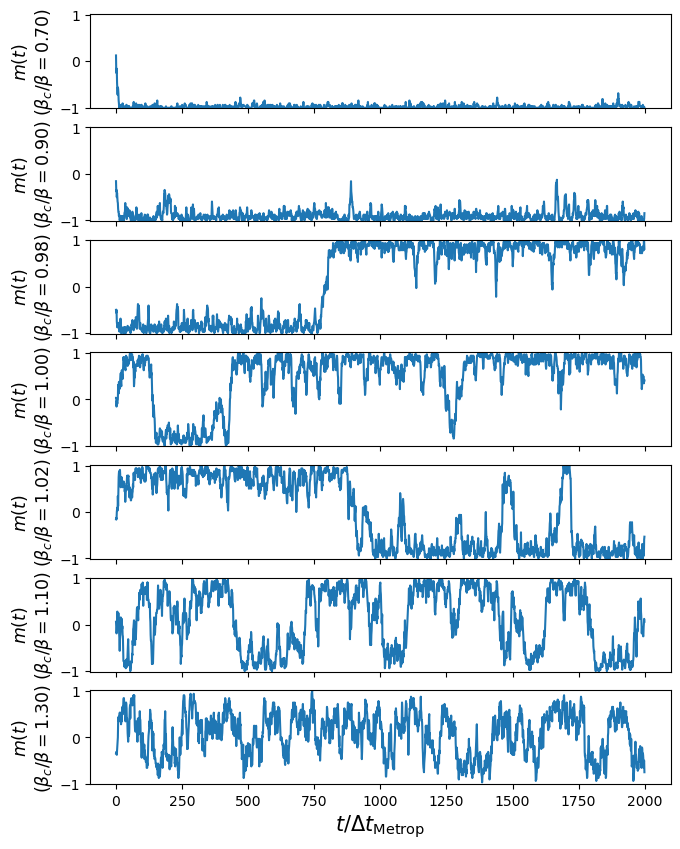

In [30]:
lattice_length = 8
fig, axes = fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    config_i = np.random.choice([-1,1], size=(lattice_length, lattice_length))

    trajectory = get_metropolis_ising_trajectory(
        initial_config = config_i,
        reduced_temperature = reduced_temperature,
        lattice_length = lattice_length,
        no_of_burn_in_steps = no_of_burn_in_steps,
        no_of_samples = no_of_samples
    )

    magnetisation = trajectory[1, :]
    axes[reduced_temperature_index].plot(magnetisation)
plt.show()

As $\frac{\beta_c}{\beta}$ increases, the magnetisation trace becomes more symmetric about $m=0.$ For low $\frac{\beta_c}{\beta}$, the chain has a single symmetry-broken mode with $m \approx ±m_*$ with little to no sign switching. In turn, there is asymmetric mixing. Around $\frac{\beta_c}{\beta} \approx 1$, there is intermittent mode switching between the $±m_*$ modes with long plateaus, signalling slow mixing. Then in the disordered phrase, for high $\frac{\beta_c}{\beta}$, $m(t)$ fluctuates around 0 highlighting symmetric mixing.

**Question 2b (ii):** Repeat the process for the $L = 32$ model. [1 mark]  

Given that we're happy with mixing around at least a single mode and won't simulate any larger systems, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ based on simulation outputs at all temperatures.  In terms of this thermalisation, how do your results differ from the $L = 8$ case?  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature - and how this compares with the $L = 8$ case. [6 marks]

Temperatures:   0%|          | 0/7 [00:00<?, ?it/s]

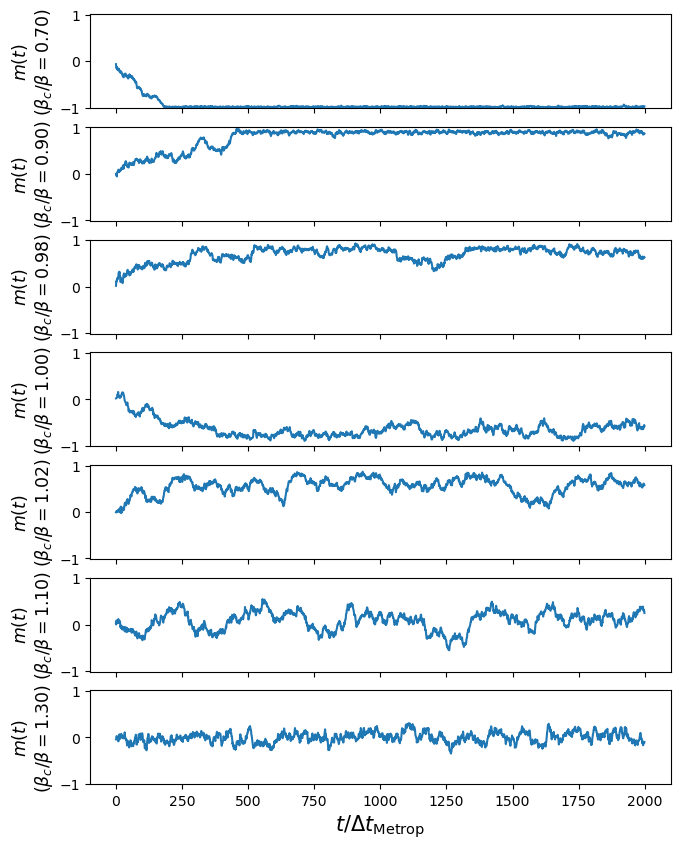

In [34]:
from tqdm.auto import tqdm # the L=32 simulations are really long! easy to visualise progress

lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(tqdm(reduced_temperatures, desc="Temperatures")):
    config_i = np.random.choice([-1,1], size=(lattice_length, lattice_length))

    trajectory = get_metropolis_ising_trajectory(
        initial_config = config_i,
        reduced_temperature = reduced_temperature,
        lattice_length = lattice_length,
        no_of_burn_in_steps = no_of_burn_in_steps,
        no_of_samples = no_of_samples
    )

    magnetisation = trajectory[1, :]
    axes[reduced_temperature_index].plot(magnetisation)
plt.show()

For $L = 32$, the chains have less symmetric mixing around $m=0$ than for $L=8$. For low $\frac{\beta_c}{\beta}$, the chain collapses into a single ordered mode at either $m(t) = 1 \text{ or } m(t) = -1$, with significantly less pertubations than the $L=8$ case. This is a result of ordered state stability from the larger lattice size. At near criticality, there are posiitve and highly correlated trajectories. In the $L=8$ case, there are periods where the chain crosses $m=0$ however in the $L=32$ case, there are no instance of crossing $m=0$ over the series of steps. At high $\frac{\beta_c}{\beta}$, mixing is more symmetric, with more drifts in trajectory path.

**Question 2b (iii):** Finally, repeat the simulations of Question 2b (ii) but starting instead from an ordered configuration. [1 mark]

What do the high-temperature simulations tell you about your choice for $n_\mathrm{burn-in}^\mathrm{Metrop}$?  [3 marks]

Temperatures:   0%|          | 0/7 [00:00<?, ?it/s]

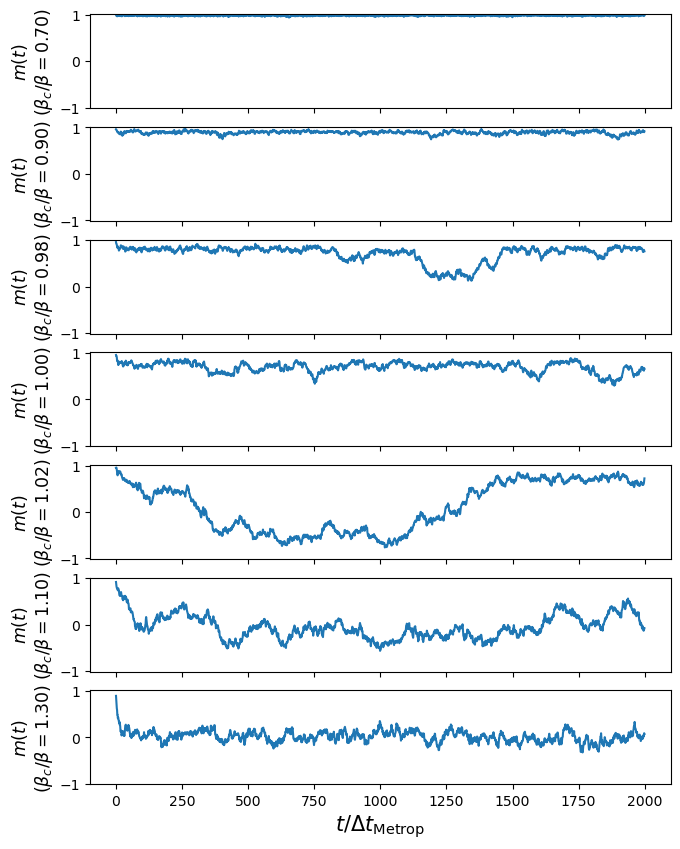

In [36]:
lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(tqdm(reduced_temperatures, desc="Temperatures")):
    config_i = np.ones((lattice_length, lattice_length), dtype=int)

    trajectory = get_metropolis_ising_trajectory(
        initial_config = config_i,
        reduced_temperature = reduced_temperature,
        lattice_length = lattice_length,
        no_of_burn_in_steps = no_of_burn_in_steps,
        no_of_samples = no_of_samples
    )
    axes[reduced_temperature_index].plot(trajectory[1, :])
    
plt.show()

For the high temperature simulations, $m(t)$ has fluctuations about $m = 0$ within the first 100 $t/\Delta t_{\text{Metrop}}$ steps, suggesting that the burn-in is sufficient.

Set your chosen $n_\mathrm{burn-in}^\mathrm{Metrop}$ for the remainder of the Metropolis part of the workbook.

In [37]:
no_of_burn_in_steps = 10 ** 3

### Part 2c: expected collective behaviour vs reduced temperature

We now move on to using our Metropolis code to make some predictions about the expected collective behaviour of the spins as a function of temperature (using equilibrated Markov chains resulting from your choice of $n_\mathrm{burn-in}$).  We will perform Metropolis simulations of the model at a variety of temperatures, to predict (as a function of reduced temperature):
1. the specific heat
2. the expected absolute magnetisation

<!--- 
Simulate the $L = 32$ model at a set of reduced temperatures, to generate samples of size $10^3$ at each temperature.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures (which will not necessarily be the same as those above).  
--->
**Question 2c:** Simulate the $L = 32$ model at each of the reduced temperatures defined in the `reduced_temperatures` Python list below.  Generate (thermalised/equilibrated) samples of size $10^3$ at each temperature, then use them to predict the above quantities.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Be sure to correctly label the axes of your figures, but don't worry about estimating or presenting errors bars for now.  We advise you to write the code that generates your predictions in the first of the two following cells, then write the code that plots the results in the second cell.  [6 marks]

Comment on whether the predictions are consistent with the existence of a phase transition (making sure to reference the $N \to \infty$ behaviour with which they are consistent). [4 marks]

**HINT:** While developing your code within the for-loop, comment out the given `lattice_length`, `no_of_samples` and `reduced_temperatures`, and set the quantities to new values such that the for-loop runs quickly.  Once you're happy with your code, reset the original values and run the code block.  These simulations 'proper' may take around 4-5 minutes.

<!--- 
Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, simulate the model at a set of seven suitably chosen reduced temperatures.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Don't worry about estimating or presenting errors bars for now.
--->

<!--- 
Comment on the quality of the predictions as a function of temperature.  Based on the relationship between the uncertainty in some estimator and its integrated autocorrelation time (IACT), what does this suggest about the sampling challenges at the different temperatures?  Finally, comment on which quantities pose the greatest challenges and suggest why this is the case.
--->

In [38]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_samples, configurational_specific_heat_samples = [], []
mean_absolute_magnetisations, specific_heats_per_spin = [], []
for reduced_temperature in tqdm(reduced_temperatures, desc="Temperatures"):
    config_i = np.random.choice([-1,1], size=(lattice_length, lattice_length))
    trajectory = get_metropolis_ising_trajectory(
        initial_config = config_i,
        reduced_temperature = reduced_temperature,
        lattice_length = lattice_length,
        no_of_burn_in_steps = no_of_burn_in_steps,
        no_of_samples = no_of_samples
    )

    energy_samples = trajectory[0, -no_of_samples:]
    magnetisation_samples = trajectory[1, -no_of_samples:]

    abs_mag_samples = np.abs(magnetisation_samples)
    absolute_magnetisation_samples.append(abs_mag_samples)
    mean_absolute_magnetisations.append(float(np.mean(abs_mag_samples)))

    temp = get_temperature(reduced_temperature)
    beta = 1.0 / temp

    u_mean = np.mean(energy_samples)
    cv_per_spin = (beta ** 2 / lattice_length ** 2) * (np.mean(energy_samples ** 2) - u_mean ** 2)
    specific_heats_per_spin.append(float(cv_per_spin))

Temperatures:   0%|          | 0/11 [00:00<?, ?it/s]

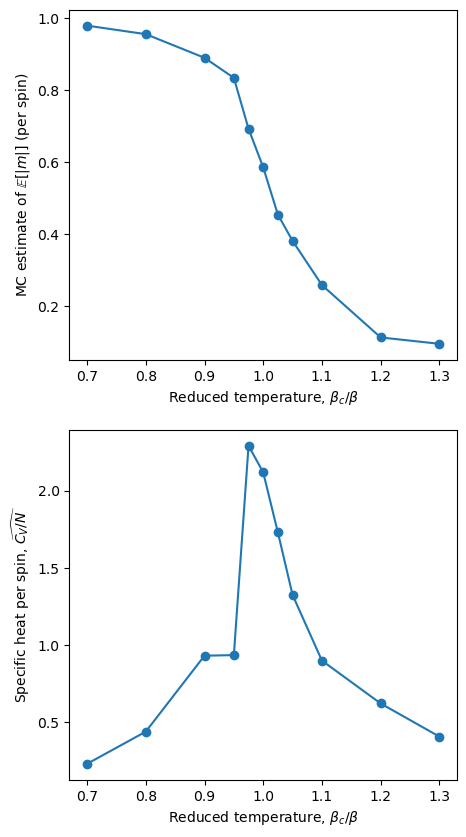

In [39]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))

axes[0].plot(reduced_temperatures, mean_absolute_magnetisations, marker="o")
axes[0].set_xlabel(r"Reduced temperature, $\beta_c/\beta$")
axes[0].set_ylabel(r"MC estimate of $\mathbb{E}[|m|]$ (per spin)")

axes[1].plot(reduced_temperatures, specific_heats_per_spin, marker="o")
axes[1].set_xlabel(r"Reduced temperature, $\beta_c/\beta$")
axes[1].set_ylabel(r"Specific heat per spin, $\widehat{C_V/N}$")

plt.show()

The MC estimation of $\mathbb{E}[\mid m \mid] \approx 1$ when the reduced temperature is less than 1, decreasing with a steep rate following $\frac{\beta_c}{\beta} > 1$. This coincides with the thermodynamic-limit magnetisation result: $\lim_{N \to \infty} \mathbb{E}[\mid m \mid] = 0$ for $\beta < \beta_c$ and positive for $\beta > \beta_c$. 

The specific heat per spin has a peak at $\frac{\beta_c}{\beta} \approx 1$. The thermodynamic limit of the 2D Ising specific heat logarithmically diverges when $\frac{\beta_c}{\beta} = 1$, representing as a large peak on the curve. The graphs shape is consistent with the $N \to \infty$ logarithmic divergence.

### Part 2d: uncertainty quantification

In Part 2c, we found that our simulations made predictions (of the expected absolute magnetisation and specific heat) that were sufficient to see some evidence of a phase transition.  This gave us an idea of how MCMC is used in practice in statistical physics.

However, you may have observed some noise in the predictions near the transition, i.e. the predictions may not reflect the true smoothly varying functions of temperature (both functions are smooth at finite $N$).  Moreover, these simulations were performed at a set of temperatures separated by relatively large increments.  If we were to increase the density of simulation temperatures near the phase transition, we would typically observe yet more noise in our predictions - and these effects additionally worsen with increasing $N$.

This uncertainty is due to strong autocorrelations in the Markov chain near the transition.  We provide a function that estimates the IACT below (which cuts off the sum over the ACF lags at the first lag at which the ACF is less than $1 / e^2$).

In [40]:
def get_integrated_autocorrelation_time(one_dimensional_sample, cutoff=math.e ** (-2)):
    autocorrelation_function = get_autocorrelation(one_dimensional_sample)
    normalised_autocorrelation_function = autocorrelation_function / autocorrelation_function[0]
    max_acf_index = [index for index, value in enumerate(normalised_autocorrelation_function) if value < cutoff][0] - 1
    return 2.0 * np.sum(normalised_autocorrelation_function[:max_acf_index]) - 1.0

def get_autocorrelation(one_dimensional_sample):
    mean_zero_sample = one_dimensional_sample - np.mean(one_dimensional_sample)
    full_acf = np.correlate(mean_zero_sample, mean_zero_sample, mode='full')
    """np.correlate() is symmetric about t = 0 when mode='full' - full_acf[full_acf.size // 2:] returns t >= 0 values"""
    return full_acf[full_acf.size // 2:]

**Question 2d:** Estimate the IACT of the absolute magnetisation at each temperature.  Present a figure plotting these IACTs against reduced temperature.  [2 marks]

Comment on what this tells us about both the uncertainity in our estimator (for the absolute magnetisation) and the effective sample size (wrt to the absolute magnetisation) as a function of temperature.  What does this mean for the predictive 'power' of Metropolis Monte Carlo as a function of temperature?  And does this align with the behaviour of the IACT (as a function of *N* and near the transition) presented in the lectures?  [8 marks]

Temperature:   0%|          | 0/11 [00:00<?, ?it/s]

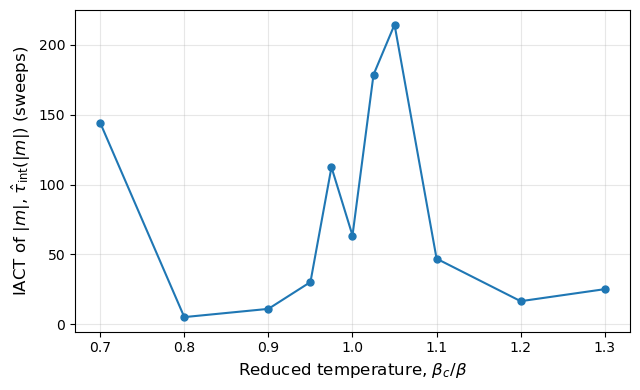

In [41]:
abs_iacts_mag = []

for rt in tqdm(reduced_temperatures, desc="Temperature"):
    init_spins = np.random.choice([-1, 1], size=(lattice_length, lattice_length))

    trajectory = get_metropolis_ising_trajectory(
        initial_config=init_spins,
        reduced_temperature=rt,
        lattice_length=lattice_length,
        no_of_burn_in_steps=no_of_burn_in_steps,
        no_of_samples=no_of_samples
    )

    equi_mag = trajectory[1, -no_of_samples:]
    abs_equi_mag = np.abs(equi_mag)

    abs_iacts_mag.append(float(get_integrated_autocorrelation_time(abs_equi_mag)))

plt.figure(figsize=(6.5, 4.0))
plt.plot(reduced_temperatures, abs_iacts_mag, marker="o", linewidth=1.5, markersize=5)
plt.xlabel(r"Reduced temperature, $\beta_c/\beta$", fontsize=12)
plt.ylabel(r"IACT of $|m|$, $\hat{\tau}_{\mathrm{int}}(|m|)$ (sweeps)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The absolute magnetisation estimator uses equilibrated Metropolis samples, given by the equation 

$$ \hat{\mu}_{\mid m \mid} = \frac{1}{n}\sum_{t=1}^n\mid m_t\mid.$$

For correlated samples, the standard error can be quantified by the proportional relation $$\text{SE}(\hat{\mu}_{\mid m \mid} \propto \sqrt{\frac{\tau_{\text{int}(\mid m \mid)}}{n}}$$ so the greater the $\tau_{\text{int}}(\mid m \mid),$ the greater the uncertainty. The uncertainty is small apart from $\beta_c/\beta \approx 1$, where there is maximal uncertainty. 

The effective sample size scales by the formula 
$$n_{\mathrm{eff}}(|m|)\approx \frac{n}{2,\tau_{\mathrm{int}}(|m|)}.$$ For small $\tau_{\mathrm{int}}(|m|)$, there is large $n_{\mathrm{eff}}$ When $\tau_{\mathrm{int}}(|m|)$ significantly increases around $\beta_c$, $n_{\mathrm{eff}}$ collapses with only a few samples behaving as independent.

The Metropolis MC algorithm is most predictive when away from the transition, as this keeps $\tau_{\mathrm{int}}(|m|)$ small and $n_{\mathrm{eff}}$ high. However, the predictive power is least reliable near the $\beta_c$, so a larger chain is needed to mitigate this.

## Part 3: Wolff Monte Carlo for the 2D Ising model

This final part of the assignment repeats the process for the Wolff algorithm.  This was the first cluster algorithm defined in the lectures.

## Part 3a: algorithm

We begin by constructing the algorithm.

**Question 3a:** Complete the `get_wolff_ising_trajectory()` function such that it generates a Wolff Monte Carlo simulation of the 2D Ising model for the given inputs [14 marks].

In [63]:
from collections import deque

def wolff_padd(beta):
    return -np.expm1(-2.0 * beta)

def wolff_cluster(config, start, p_add, L):
    cluster = np.zeros((L, L), dtype=bool)
    cluster[start] = True
    q = deque([start])

    seed_spin = config[start]

    while q:
        site = q.pop()  # DFS; use popleft() for BFS
        for nb in (
            get_east_neighbour(site, L),
            get_west_neighbour(site, L),
            get_north_neighbour(site, L),
            get_south_neighbour(site, L),
        ):
            if (not cluster[nb]) and (config[nb] == seed_spin) and (np.random.rand() < p_add):
                cluster[nb] = True
                q.append(nb)

    return cluster

def get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    config = initial_config.copy()
    L = lattice_length
    N = L * L

    T = get_temperature(reduced_temperature)
    beta = 1.0 / T
    p_add = wolff_padd(beta)

    n_steps = no_of_burn_in_steps + no_of_samples
    potential_trajectory = []
    magnetisation_trajectory = []

    # so my code didn't originally work with the provided function get_potential
    # but it works significantly faster with this vectorised approach
    # could be a kernel issue. 
    
    def potential_fast(x):
        return -float(np.sum(x * (np.roll(x, -1, axis=0) + np.roll(x, -1, axis=1))))

    total_mag = int(np.sum(config))

    for _ in range(n_steps):
        start = (np.random.randint(L), np.random.randint(L))

        cluster = wolff_cluster(config, start, p_add, L)
        cluster_size = int(cluster.sum())

        s_0 = int(config[start])
        total_mag += -2 * s_0 * cluster_size
        config[cluster] *= -1

        potential_trajectory.append(potential_fast(config))
        magnetisation_trajectory.append(total_mag / N)

    return np.array([potential_trajectory, magnetisation_trajectory])


Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [64]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

In [65]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

**Question 3b:** Similarly to Question 2b, perform a single Wolff simulation of the $L = 32$ model at each of the reduced temperatures given below (starting from a random configuration each time).  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Wolff}$ (assuming we won't simulate at larger system sizes).  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature, explaining and reflecting on the poorer mixing at high temperature.  Comment on how the results compare with the Metropolis case in general. [8 marks]

Temperature Loop: 100%|██████████| 7/7 [00:01<00:00,  3.74it/s]


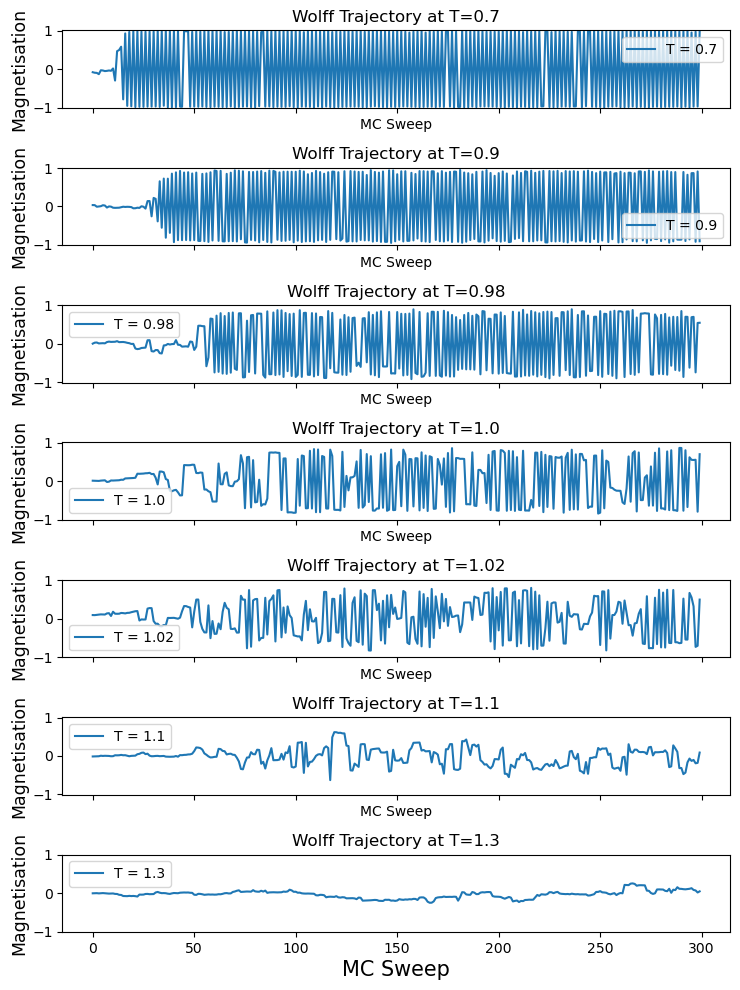

In [68]:
lattice_length = 32
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 200
no_of_samples = 100

fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(tqdm(reduced_temperatures, desc="Temperature Loop")):

    
    config_i = np.random.choice([-1, 1], size=(lattice_length, lattice_length))
    
    trajectory = get_wolff_ising_trajectory(
        config_i, 
        reduced_temperature, 
        lattice_length, 
        no_of_burn_in_steps=0,         # Set to 0 so we see the initial equilibration in the plot
        no_of_samples=no_of_burn_in_steps + no_of_samples
    )
    
    magnetisation_history = trajectory[1, :]
    
    ax = axes[reduced_temperature_index]
    ax.plot(magnetisation_history, label=f'T = {reduced_temperature}')
    ax.set_ylabel("Magnetisation")
    ax.set_xlabel("MC Sweep")
    ax.set_title(f"Wolff Trajectory at T={reduced_temperature}")
    ax.legend()
    

plt.tight_layout()
plt.show()

For low temperature $T$ in the ordered phase, the trajectory jumps between large positive and negative magnetisations: this visually shows the chain exploring both modes frequently, with strong symmetry. When spins are strongly correlated, the Wolff algorithm flips large clusters. Near criticality, the trajectory maintains a frequent, jagged trajectory, showing good mixing. In comparison, the Metropolis approach showed significant slowing, generally committing to sustained positive or negative values for the majority of the trajectory, whereas the Wolff approach shows continued mobility. For large $T$, the trajectory has little amplitude: this is a result of small clustering and thus a smaller number of flips.

Set your chosen $n_\mathrm{burn-in}^\mathrm{Wolff}$ for the remainder of the Wolff part of the workbook.

In [69]:
no_of_wolff_burn_in_steps = 500

### Part 3c: expected collective behaviour vs reduced temperature

Here we repeat Part 2c but using the Wolff algorithm.  This should result in higher quality preductions about the expected collective behaviour of the spins near the transition.

**Question 3c:** Repeat the coding part of Question 2c but with the Wolff algorithm in place of the Metropolis algorithm.  [5 marks]

Comment on any qualitative differences with your Metropolis results (from Question 2c).  Does this provide better or worse evidence for the phase transition?  [4 marks]

In [70]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_samples, configurational_specific_heat_samples = [], []
mean_absolute_magnetisations, specific_heats_per_spin = [], []
for reduced_temperature in tqdm(reduced_temperatures, desc="Temperatures"):
    config_i = np.random.choice([-1,1], size=(lattice_length, lattice_length))
    trajectory = get_wolff_ising_trajectory(
        initial_config = config_i,
        reduced_temperature = reduced_temperature,
        lattice_length = lattice_length,
        no_of_burn_in_steps = no_of_burn_in_steps,
        no_of_samples = no_of_samples
    )

    energy_samples = trajectory[0, -no_of_samples:]
    magnetisation_samples = trajectory[1, -no_of_samples:]

    abs_mag_samples = np.abs(magnetisation_samples)
    absolute_magnetisation_samples.append(abs_mag_samples)
    mean_absolute_magnetisations.append(float(np.mean(abs_mag_samples)))

    temp = get_temperature(reduced_temperature)
    beta = 1.0 / temp

    u_mean = np.mean(energy_samples)
    cv_per_spin = (beta ** 2 / lattice_length ** 2) * (np.mean(energy_samples ** 2) - u_mean ** 2)
    specific_heats_per_spin.append(float(cv_per_spin))

Temperatures: 100%|██████████| 11/11 [00:13<00:00,  1.23s/it]


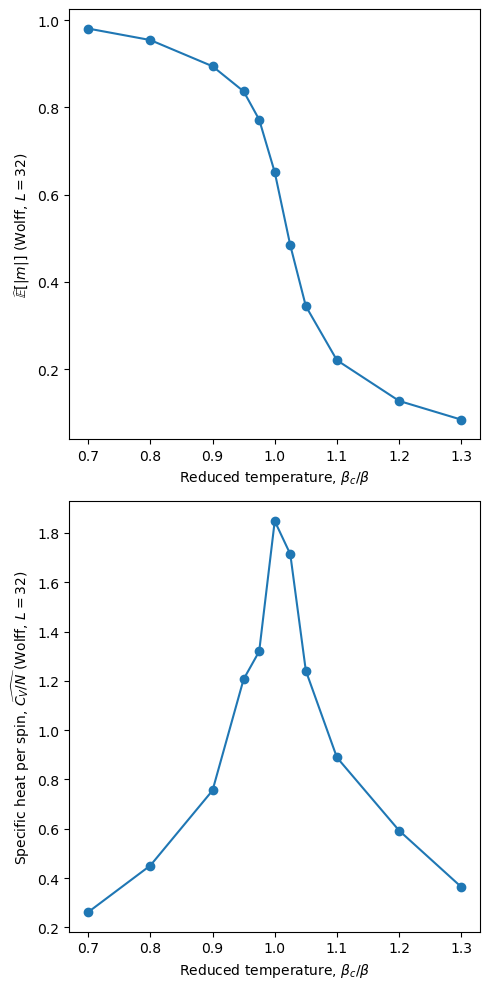

In [73]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))

axes[0].plot(reduced_temperatures, mean_absolute_magnetisations, marker="o")
axes[0].set_xlabel(r"Reduced temperature, $\beta_c/\beta$")
axes[0].set_ylabel(r"$\widehat{\mathbb{E}}[|m|]$ (Wolff, $L=32$)")

axes[1].plot(reduced_temperatures, specific_heats_per_spin, marker="o")
axes[1].set_xlabel(r"Reduced temperature, $\beta_c/\beta$")
axes[1].set_ylabel(r"Specific heat per spin, $\widehat{C_V/N}$ (Wolff, $L=32$)")

plt.tight_layout()
plt.show()

The nature of the curves are qualitatively similar: when $\beta_c/\beta \approx 1$, Wolff's algorithm has a slightly more stable curve for both the specific heat per spin and the estimate of $\mathbb{E}[|mm|]$. Wolff shows a cleaner phase transition than Metropolis.

### Part 3d: uncertainty quantification

In Part 3c, we found that our Wolff simulations made significantly improved predictions (of the expected absolute magnetisation and specific heat) relative to the Metropolis predictions of Part 2c.  This suggests that the Wolff algorithm generates Markov chains with lower autocorrelation than the Metropolis algorithm (at least near the transition).

To quantify its autocorrelation/uncertainty, here we repeat Part 2d but using the Wolff algorithm.

**Question 3d:** Repeat Question 2d with the Wolff algorithm in place of the Metropolis algorithm, but plot the resultant IACTs vs reduced temperature for both the Wolff and Metropolis simulations on the same figure.  [3 marks]

Comment on what these IACT results tell us about both the uncertainity in each estimator and the effective sample size (wrt to each quantity) as a function of temperature.  What does this mean for the predictive 'power' of Wolff Monte Carlo relative to Metropolis Monte Carlo as a function of temperature? [8 marks]

IACT over Temperatures: 100%|██████████| 11/11 [03:07<00:00, 17.08s/it]


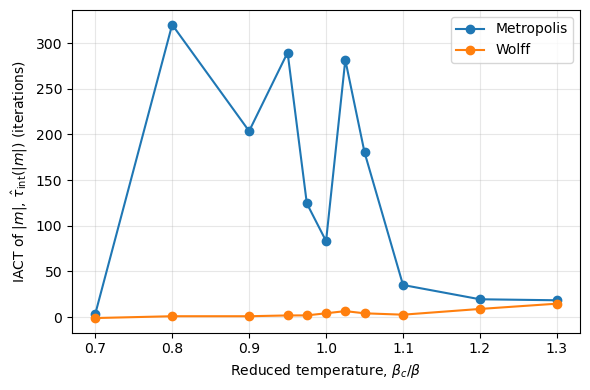

In [74]:
abs_iacts_mag_metrop = []
abs_iacts_mag_wolff = []

for reduced_temperature in tqdm(reduced_temperatures, desc="IACT over Temperatures"):
    config0 = np.random.choice([-1, 1], size=(lattice_length, lattice_length))

    traj_metrop = get_metropolis_ising_trajectory(
        initial_config=config0,
        reduced_temperature=reduced_temperature,
        lattice_length=lattice_length,
        no_of_burn_in_steps=no_of_burn_in_steps,
        no_of_samples=no_of_samples
    )

    traj_wolff = get_wolff_ising_trajectory(
        initial_config=config0,
        reduced_temperature=reduced_temperature,
        lattice_length=lattice_length,
        no_of_burn_in_steps=no_of_burn_in_steps,
        no_of_samples=no_of_samples
    )

    equi_mag_metrop = traj_metrop[1, no_of_burn_in_steps:]
    equi_mag_wolff = traj_wolff[1, no_of_burn_in_steps:]

    abs_equi_mag_metrop = np.abs(equi_mag_metrop)
    abs_equi_mag_wolff = np.abs(equi_mag_wolff)

    abs_iacts_mag_metrop.append(get_integrated_autocorrelation_time(abs_equi_mag_metrop))
    abs_iacts_mag_wolff.append(get_integrated_autocorrelation_time(abs_equi_mag_wolff))

fig, ax = plt.subplots(figsize=(6.0, 4.0))
ax.plot(reduced_temperatures, abs_iacts_mag_metrop, marker="o", label="Metropolis")
ax.plot(reduced_temperatures, abs_iacts_mag_wolff, marker="o", label="Wolff")
ax.set_xlabel(r"Reduced temperature, $\beta_c/\beta$")
ax.set_ylabel(r"IACT of $|m|$, $\hat{\tau}_{\mathrm{int}}(|m|)$ (iterations)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The uncertainties for both Metropolis and Wolff are illustrated in the plot above; for the Metropolis algorithm, the uncertainty is large! Whereas with the Wolff aproach, the uncertainty remains small, rising to around 10 for high reduced temperature. Wolff's algorithm provides stronger predictive power given the reliability of prediction with more independent samples.

In [ ]:
# import the necessary libraries
import math 
import numpy as np
import matplotlib.pyplot as plt
import random

In [ ]:
random.seed(1234) # set the seed for automated marking (do not delete)

In [ ]:
# Please enter your name as a string in the box below, in case files go astray.

NAME = "[ENTER NAME]"

# A1 Uncertainty quantification and cluster algorithms

**Dr Michael Faulkner**

## Submission

This is the first assignment, worth 1.2 CATs of the 15-credit version of the module.

Before you submit this assignment, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE".

You should submit your completed notebook via the nbgrader interface.  Once finished, go back to the Assignments tab and click submit.  You can repeat this process if you are not happy with your original submission.  This submits a version of the notebook with all outputs cleared.

Feedback will be released through the nbgrader interface.  You will be able to download this from the Assignments tab.

**IMPORTANT:** 
1) Students **should not** duplicate cells as duplicated cells are very difficult to manage during the marking process.  As such, duplicated cells **will not be considered** for marking.
2) Be sure to use the *Standard Python 3* server in Noteable as there was a recent a bug (in Notable) that has been fixed on this server (*Language and Machine Learning* works as a backup).


## Overview

This assignment aims to deepen your understanding of Markov-chain Monte Carlo (MCMC), the relationship between uncertainty and autocorrelation in MCMC - and how strong autocorrelations in Metropolis MC of the 2D Ising model can be circumvented by cluster algorithms.  We concentrate on the following tasks:

1) Setup some key functions for MCMC simulations of the 2D Ising model.  These include the nearest neighbours on the periodic lattice, the potential energy and the magnetisation.

2) Metropolis Monte Carlo (MC) for the 2D Ising model
- Implement the Metropolis algorithm for the 2D Ising model.
- Plot the trace of the magnetisation (i.e. the magnetisation vs MC time) at a variety of temperatures - this will help us to understand how long we need to run the algorithm to equilibrate the system.
- Use the algorithm to predict the expected absolute magnetisation and specific heat at a variety of temperatures.
- At those same temperatures, estimate the integrated autocorrelation time and comment qualitatively on all three results in terms of UQ.

3) Wolff Monte Carlo for the 2D Ising model
- Follow the same process for the Wolff algorithm.
- Comment qualitatively on any differences between the results.

## Part 1: 2D Ising model: definition and key functions

As described in the lectures, the 2D Ising model is a magnetic spin model defined on an *N*-site periodic square lattice with interaction potential
$$
U_{\rm Ising} := -J \sum_{<i,j>} x_i x_j ,
$$
where $x_i = \pm 1$ is the spin value at site $i \in \{ 1, \dots  , N\}$, the sum $\sum_{<i,j>}$ is over all nearest-neighbour pairs (of sites) and $J > 0$ is the exchange constant with units of energy (meaning that $\beta J$ is dimensionless) which we set to one.

### Part 1a: periodic lattice

To simplify the labelling of the lattice sites, we introduce the integer lattice length $L \in \mathbb{N}$ such that $N = L\mathrm{x}L$ and represent each lattice site with a 2D Python tuple of length 2, where the x/y component of the tuple is an element of $\{0, ..., L - 1\}$ representing the x/y index of the lattice site.  For example, `lattice_site = (0, 0)` represents the site at the $(0, 0)$ coordinate of the lattice.

(We will also use this formulation to define each spin configuration as a 2D numpy array of shape $(L, L)$.)

Below we define the `get_lattice_sites()` function such that it outputs a 1D Python list `lattice_sites` that contains the tuples that denote the lattice sites, i.e. 

`lattice_sites = [(0, 0), ... ,(0, lattice_length - 1), (1, 0), ... ,(1, lattice_length - 1), ... , (lattice_length - 1, 0), ... (lattice_length - 1, lattice_length - 1)]`.

Moreover, it's important to correctly define the nearest neighbours of each lattice site while accounting for the periodicity of the lattice.  The question below asks you to complete the following nearest-neighbour functions such that, e.g. the eastern neighbour of lattice site `(L - 1, 0)` is `(0, 0)`.

**Question 1a:** Complete the two empty nearest-neighbour functions [4 marks].

In [ ]:
def get_lattice_sites(lattice_length):
    return [(site_index_x, site_index_y) for site_index_x in range(lattice_length) for site_index_y in range(lattice_length)]


def get_east_neighbour(lattice_site, lattice_length):
    r"""Returns the eastwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0] + (lattice_site[0] + 1) % lattice_length - lattice_site[0] % lattice_length, 
            lattice_site[1])


def get_north_neighbour(lattice_site, lattice_length):
    r"""Returns the northwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    # YOUR CODE HERE
    raise NotImplementedError()


def get_west_neighbour(lattice_site, lattice_length):
    r"""Returns the westwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    # YOUR CODE HERE
    raise NotImplementedError()


def get_south_neighbour(lattice_site, lattice_length):
    r"""Returns the southwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0], lattice_site[1] + (lattice_site[1] - 1 + lattice_length) % lattice_length - 
            (lattice_site[1] + lattice_length) % lattice_length)

def get_neighbours(lattice_site, lattice_length):
    r"""Returns a list of the four nearest neighbours (on the 2D lattice) of lattice_site = (site_index_x, site_index_y),
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return [get_east_neighbour(lattice_site, lattice_length), get_north_neighbour(lattice_site, lattice_length),
            get_west_neighbour(lattice_site, lattice_length), get_south_neighbour(lattice_site, lattice_length)]


Here we test your code.

In [ ]:
lattice_length = 8

In [ ]:
test_site = (0, 0)
target_neighbour = (0, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 1, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, lattice_length - 1)
target_neighbour = (0, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, 0)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 2, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, lattice_length - 1)
target_neighbour = (lattice_length - 1, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 2, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

### Part 1b: potential energy and magnetisation

Three key quantities of interest the current value of the potential (energy), the current value of the magnetisation and the potential difference (the difference in the potential energy between the current and candidate spin configurations).  The potential $U_{\rm Ising}$ is defined above and the magnetisation $m := \sum_{j = 1}^N x_j / N$ is the (configurational) mean value of the spins.

**Question 1b (i):**  With `config` a 2D numpy array of shape `(lattice_length, lattice_length)` defined such that `config[i, j]` is the ($\pm 1$) spin value at lattice site `(i, j)`, complete the two empty functions below.  Full marks are awarded for a `get_potential_difference()` function that uses only the spin values of the active spin and its nearest neighbours, n.b. not doing this (e.g. using `get_potential()` within `get_potential_difference()`) **can lead to errors when running the Metropolis simulations below**. [4 marks]

In [ ]:
def get_potential(config, lattice_length):
    """
    Returns the potential energy for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential energy.
    """
    return - float(np.sum([config[lattice_site] * config[get_east_neighbour(lattice_site, lattice_length)] + 
                           config[lattice_site] * config[get_north_neighbour(lattice_site, lattice_length)]
                           for lattice_site in get_lattice_sites(lattice_length)]))


def get_magnetisation(config):
    """
    Returns the magnetisation for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).

    Returns
    -------
    float
        The magnetisation.
    """
    # YOUR CODE HERE
    raise NotImplementedError()


def get_potential_difference(config, active_lattice_site, lattice_length):
    """
    Returns the potential difference resulting from flipping the single active spin.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    active_lattice_site : (int, int)
        The lattice site of the active spin.
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential difference resulting from flipping the single active spin.
    """
    # YOUR CODE HERE
    raise NotImplementedError()

Here we test your code.

In [ ]:
lattice_length = 4
config = np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = 1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = -np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = -1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = np.array([[1, -1, -1, -1], [1, -1, 1, -1], [-1, -1, 1, 1], [1, -1, -1, 1]])
active_lattice_site = (0, 1)
target_magnetisation = -0.125
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = np.array([[1, -1, 1, -1], [1, 1, 1, 1], [-1, 1, 1, -1], [-1, 1, 1, -1]])
active_lattice_site = (lattice_length - 1, lattice_length - 1)
target_magnetisation = 0.25
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

**Question 1b (ii):** Question 1b (i) states that using `get_potential()` within `get_potential_difference()` can lead to errors when running the Metropolis simulations below.  Comment on why this is the case.  [3 marks]

YOUR ANSWER HERE

### Part 1c: phase transition

Building on the initial work of Kramers & Wannier [1], Onsager [2] showed that the 2D Ising model can also be solved analytically, which is quite rare in statistical physics!  The thermodynamic limit of the specific heat (defined in general in the lectures) per particle is 
$$
\lim_{N \to \infty} \left(\frac{1}{N} C_V(\beta, J, N) \right) = \beta^2 \partial_{\beta}^2 \gamma(\beta J) ,
$$
where $\beta := k_\mathrm{B}T$ is the *inverse temperature* (with $T \in (0, \infty)$ the *temperature* and $k_\mathrm{B} > 0$ the *Boltzmann constant*) and 
$$
\gamma(\beta J) := \ln \left( 2\cosh (2\beta J) \right) + \frac{1}{\pi} \int_0^{\pi / 2} \ln \left[ \frac{1}{2} \left( 1 + \sqrt{1 - \frac{4 \sinh^2 (2\beta J) \sin^2w}{\cosh^4 (2\beta J)}} \right) \right] dw .
$$
This showed that the thermodynamic specific heat per particle diverges logarithmically at the *inverse critical temperature* $\beta_{\rm c} := \ln (1 + \sqrt{2}) / (2J)$.  This predicts a *phase transition* at $\beta = \beta_{\rm c}$, since a phase transition is some point in thermodynamic phase space (in this case, the support of $\beta \in (0, \infty)$) at which some expectation becomes non-analytic (e.g. discontinuous, non-smooth, divergent) in the thermodynamic limit. 

In addition, the magnetisation can also be used to demonstrate the phase transition, where Onsager [3] and Yang [4] proved a non-differentiability in its expected absolute value in the thermodynamic limit:
$$
\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = \left( 1 - (\sinh (2 \beta J))^{-4} \right)^{1 / 8}
$$
for all $\beta > \beta_{\rm c}$ (the *low-temperature phase*) and $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = 0$ for all $\beta < \beta_{\rm c}$ (the *high-temperature phase*).  This provided further evidence of the phase transition at $\beta = \beta_{\rm c}$ with the additional insight that it is one between a low-temperature ($\beta > \beta_{\rm c}$) *ferromagnetic* (ordered) phase and a high-temperature ($\beta < \beta_{\rm c}$) *paramagnetic* (disordered) one.  Moreover, the phase transition is classed as *continuous* because $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N)$ is continuous at the phase transition, despite not being smooth (i.e. differentiable).

[1] Kramers & Wannier, *Phys. Rev.* 60, 252 (1941); *Phys. Rev.* 60, 263 (1941)

[2] Onsager, *Phys. Rev.* 65, 117 (1944)

[3] Onsager, *Nuovo Cimento* 6, 251 (1949)

[4] Yang, *Phys. Rev.* 85, 808 (1952)

**Question 1c:** Based on our discussions (during the lectures) regarding the spin-flip symmetry of the model, comment on why $\mathbb{E}m$ cannot be used to identify the phase transition, despite $\mathbb{E}|m|$ being one of its key indicators. [2 marks]

YOUR ANSWER HERE

### Part 1d: additional provided functions

As the expected collective behaviour of the microscopic spin interactions (i.e. the expected macroscopic physics) changes significantly at the phase transition, we define the model with respect to the *reduced temperature* $\tilde{T} := \beta_{\rm c} / \beta = T / T_{\rm c}$.  The phase transition then occurs at $\tilde{T} = 1$.

To simplify our code, we therefore provide the following function to map from the reduced temperature to the temperature defined in units of the exchange constant per (the) Boltzmann constant.

In [ ]:
def get_temperature(reduced_temperature):
    """
    Returns the temperature in units of the exchange constant per (the) Boltzmann constant (for a given 
        input reduced_temperature).

    Parameters
    ----------
    reduced_temperature : float
        The reduced temperature.

    Returns
    -------
    float
        The temperature in units of the exchange constant per (the) Boltzmann constant.
    """
    return reduced_temperature * (2.0 / math.log(1 + 2 ** 0.5))

As the associated terminology can be a little confusing, we also provide a function that maps from a sample of the potential to a sample of the (configurational) specific heat

Note that the configurational version of some expected quantity is a function of the current system state - and is defined such that its expectation gives the expected quantity itself.  So defining the configurational specific heat as $c_V$ means that $C_V = \mathbb{E} c_V$.

<!--- 
As the associated terminology can be a little confusing, we also provide functions that map from:
1. a sample of the absolute magnetisation to a sample of the (configurational) absolute-magnetic susceptibility
2. a sample of the potential to a sample of the (configurational) specific heat

Note also that the absolute-magnetic susceptibility 
$$
\chi_{|m|} := \beta N \, \mathrm{Var}|m| 
$$
measures fluctuations in the absolute magnetisation (and is closely related to the response of $\mathbb{E}m$ to an externally applied magnetic field).
--->

In [ ]:
def get_specific_heat_sample(potential_sample, reduced_temperature):
    """
    Returns the sample of the configurational specific heat corresponding to a given sample of the potential.

    Parameters
    ----------
    potential_sample : numpy.ndarray
        The input sample of the potential.  A one-dimensional numpy array (of floats) of length equal to the 
        sample size.
    reduced_temperature : float
        The (reduced) sampling temperature.
    lattice_length : int
        The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    numpy.ndarray
        The sample of the onfigurational specific heat.  A one-dimensional numpy array (of floats) of length 
        equal to the sample size.
    """
    return (potential_sample - np.mean(potential_sample)) ** 2 / get_temperature(reduced_temperature) ** 2

## Part 2: Metropolis Monte Carlo for the 2D Ising model

As set out in detail in the lectures, the Metropolis algorithm can be applied to generate a sample of the 2D Ising model by constructing a Markov chain.

### Part 2a: algorithm

We begin by constructing the algorithm.

**Question 2a:** Complete the function `get_metropolis_ising_trajectory()` such that it generates a Metropolis Monte Carlo simulation of the 2D Ising model for the given inputs.  [6 marks]

**HINT:** if your Metropolis accept/reject step is throwing errors, try splitting it into its two components.

In [ ]:
def get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    r"""This function generates a single trajectory of a Metropolis MC simulation of the 2D Ising model on an 
            (lattice_length x lattice_length) periodic lattice at the given reduced_temperature.
        
        Parameters
        ----------
        initial_config : numpy.ndarray
            The initial spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
            element (i, j) is an integer and represents the spin value at lattice site (i, j).
        reduced_temperature : float
            The (reduced) sampling temperature.
        lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / magnetisation at Monte Carlo iteration i.
    """
    config = initial_config
    temperature = get_temperature(reduced_temperature)
    no_of_sites = lattice_length ** 2
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    no_of_accepted_metrop_proposals = 0
    potential_trajectory, magnetisation_trajectory = [], []

    for markov_chain_index in range(no_of_mc_sweeps):
        if markov_chain_index == no_of_burn_in_steps:
            no_of_accepted_metrop_proposals = 0
        for _ in range(no_of_sites):
            # YOUR CODE HERE
            raise NotImplementedError()
        potential_trajectory.append(get_potential(config, lattice_length))
        magnetisation_trajectory.append(get_magnetisation(config))
    return np.array([potential_trajectory, magnetisation_trajectory])

We now define a function that will test your code.

In [ ]:
def test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin, 
                           expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, 
                           metrop=True):
    if metrop:
        trajectory = get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                     no_of_burn_in_steps, no_of_samples)
    else:
        trajectory = get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                no_of_burn_in_steps, no_of_samples)
    (potential_trajectory, magnetisation_trajectory) = trajectory
    potential_sample = potential_trajectory[no_of_burn_in_steps:]
    specific_heat_sample = get_specific_heat_sample(potential_sample, reduced_temperature)
    magnetisation_sample = magnetisation_trajectory[no_of_burn_in_steps:]
    simulation_mean_potential_per_spin = np.mean(potential_sample) / (lattice_length ** 2)
    simulated_specific_heat_per_spin = np.mean(specific_heat_sample) / (lattice_length ** 2)
    simulation_mean_absolute_magnetisation = np.mean(np.abs(magnetisation_sample))
    
    assert abs(simulation_mean_potential_per_spin / expected_potential_per_spin - 1.0) < 0.05, \
        (f"The simulation mean of the potential per spin (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_potential_per_spin} but its expected value is {expected_potential_per_spin}.")
    
    assert abs(simulated_specific_heat_per_spin / specific_heat_per_spin - 1.0) < 0.35, \
        (f"The simulated specific heat (at reduced_temperature = {reduced_temperature:.5f}) is "
         f"{simulated_specific_heat_per_spin} but its expected value is {specific_heat_per_spin}.")
    
    assert abs(simulation_mean_absolute_magnetisation / expected_absolute_magnetisation - 1.0) < 0.02, \
        (f"The simulation mean of the absolute magnetisation (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_absolute_magnetisation} but its expected value is {expected_absolute_magnetisation}.")

Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [ ]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

In [ ]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

### Part 2b: thermalisation/equilibration

We'll now perform some diagnostic tests to understand what a reasonable choice would be for $n_\mathrm{burn-in}^\mathrm{Metrop}$.

Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, we will focus on simulating the model at the set of seven suitably chosen reduced temperatures around the phase transition.  This is provided below, along with a function that creates a figure in which to plot our quantity of interest at each temperature.

In [ ]:
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 10 ** 3
no_of_samples = 10 ** 3 

def make_empty_multi_temperature_trace_plot_figs(reduced_temperatures):
    fig, axes = plt.subplots(len(reduced_temperatures), figsize=(7.5, 10.0))
    axes[len(reduced_temperatures) - 1].set_xlabel(r"$t / \Delta t_{\rm Metrop}$", fontsize=15.0, labelpad=3)
    [axis.set_ylim([-1.01, 1.01]) for axis in axes.flatten()]
    [axes[temperature_index].tick_params(labelbottom=False) for temperature_index in range(len(reduced_temperatures) - 1)]
    for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
        axes[reduced_temperature_index].set_ylabel(fr"$m(t)$" + "\n" + fr"($\beta_c / \beta = {reduced_temperature:.2f}$)", 
                                                   fontsize=12.5, labelpad=3)
    return fig, axes

**Question 2b (i):** Starting from a random configuration each time, perform a single Metropolis simulation of the $L = 8$ model at each of these temperatures.  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Given that we're happy to accept mixing around at least a single mode, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ at this system size.  Comment also on how well the simulations mix symmetrically (i.e. around $m = 0$) as a function of temperature. [4 marks]

In [ ]:
lattice_length = 8
fig, axes = fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

**Question 2b (ii):** Repeat the process for the $L = 32$ model. [1 mark]  

Given that we're happy with mixing around at least a single mode and won't simulate any larger systems, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ based on simulation outputs at all temperatures.  In terms of this thermalisation, how do your results differ from the $L = 8$ case?  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature - and how this compares with the $L = 8$ case. [6 marks]

In [ ]:
lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

**Question 2b (iii):** Finally, repeat the simulations of Question 2b (ii) but starting instead from an ordered configuration. [1 mark]

What do the high-temperature simulations tell you about your choice for $n_\mathrm{burn-in}^\mathrm{Metrop}$?  [3 marks]

In [ ]:
lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

Set your chosen $n_\mathrm{burn-in}^\mathrm{Metrop}$ for the remainder of the Metropolis part of the workbook.

In [ ]:
no_of_burn_in_steps = 10 ** 3

### Part 2c: expected collective behaviour vs reduced temperature

We now move on to using our Metropolis code to make some predictions about the expected collective behaviour of the spins as a function of temperature (using equilibrated Markov chains resulting from your choice of $n_\mathrm{burn-in}$).  We will perform Metropolis simulations of the model at a variety of temperatures, to predict (as a function of reduced temperature):
1. the specific heat
2. the expected absolute magnetisation

<!--- 
Simulate the $L = 32$ model at a set of reduced temperatures, to generate samples of size $10^3$ at each temperature.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures (which will not necessarily be the same as those above).  
--->
**Question 2c:** Simulate the $L = 32$ model at each of the reduced temperatures defined in the `reduced_temperatures` Python list below.  Generate (thermalised/equilibrated) samples of size $10^3$ at each temperature, then use them to predict the above quantities.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Be sure to correctly label the axes of your figures, but don't worry about estimating or presenting errors bars for now.  We advise you to write the code that generates your predictions in the first of the two following cells, then write the code that plots the results in the second cell.  [6 marks]

Comment on whether the predictions are consistent with the existence of a phase transition (making sure to reference the $N \to \infty$ behaviour with which they are consistent). [4 marks]

**HINT:** While developing your code within the for-loop, comment out the given `lattice_length`, `no_of_samples` and `reduced_temperatures`, and set the quantities to new values such that the for-loop runs quickly.  Once you're happy with your code, reset the original values and run the code block.  These simulations 'proper' may take around 4-5 minutes.

<!--- 
Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, simulate the model at a set of seven suitably chosen reduced temperatures.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Don't worry about estimating or presenting errors bars for now.
--->

<!--- 
Comment on the quality of the predictions as a function of temperature.  Based on the relationship between the uncertainty in some estimator and its integrated autocorrelation time (IACT), what does this suggest about the sampling challenges at the different temperatures?  Finally, comment on which quantities pose the greatest challenges and suggest why this is the case.
--->

In [ ]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_samples, configurational_specific_heat_samples = [], []
mean_absolute_magnetisations, specific_heats_per_spin = [], []
for reduced_temperature in reduced_temperatures:
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

### Part 2d: uncertainty quantification

In Part 2c, we found that our simulations made predictions (of the expected absolute magnetisation and specific heat) that were sufficient to see some evidence of a phase transition.  This gave us an idea of how MCMC is used in practice in statistical physics.

However, you may have observed some noise in the predictions near the transition, i.e. the predictions may not reflect the true smoothly varying functions of temperature (both functions are smooth at finite $N$).  Moreover, these simulations were performed at a set of temperatures separated by relatively large increments.  If we were to increase the density of simulation temperatures near the phase transition, we would typically observe yet more noise in our predictions - and these effects additionally worsen with increasing $N$.

This uncertainty is due to strong autocorrelations in the Markov chain near the transition.  We provide a function that estimates the IACT below (which cuts off the sum over the ACF lags at the first lag at which the ACF is less than $1 / e^2$).

In [ ]:
def get_integrated_autocorrelation_time(one_dimensional_sample, cutoff=math.e ** (-2)):
    autocorrelation_function = get_autocorrelation(one_dimensional_sample)
    normalised_autocorrelation_function = autocorrelation_function / autocorrelation_function[0]
    max_acf_index = [index for index, value in enumerate(normalised_autocorrelation_function) if value < cutoff][0] - 1
    return 2.0 * np.sum(normalised_autocorrelation_function[:max_acf_index]) - 1.0

def get_autocorrelation(one_dimensional_sample):
    mean_zero_sample = one_dimensional_sample - np.mean(one_dimensional_sample)
    full_acf = np.correlate(mean_zero_sample, mean_zero_sample, mode='full')
    """np.correlate() is symmetric about t = 0 when mode='full' - full_acf[full_acf.size // 2:] returns t >= 0 values"""
    return full_acf[full_acf.size // 2:]

**Question 2d:** Estimate the IACT of the absolute magnetisation at each temperature.  Present a figure plotting these IACTs against reduced temperature.  [2 marks]

Comment on what this tells us about both the uncertainity in our estimator (for the absolute magnetisation) and the effective sample size (wrt to the absolute magnetisation) as a function of temperature.  What does this mean for the predictive 'power' of Metropolis Monte Carlo as a function of temperature?  And does this align with the behaviour of the IACT (as a function of *N* and near the transition) presented in the lectures?  [8 marks]

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

## Part 3: Wolff Monte Carlo for the 2D Ising model

This final part of the assignment repeats the process for the Wolff algorithm.  This was the first cluster algorithm defined in the lectures.

## Part 3a: algorithm

We begin by constructing the algorithm.

**Question 3a:** Complete the `get_wolff_ising_trajectory()` function such that it generates a Wolff Monte Carlo simulation of the 2D Ising model for the given inputs [14 marks].

In [ ]:
def get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    r"""This function generates a single trajectory of a Wolff MC simulation of the 2D Ising model on an 
            (lattice_length x lattice_length) periodic lattice at the given reduced_temperature.
        
        Parameters
        ----------
        initial_config : numpy.ndarray
            The initial configuration of the system.  A two-dimensional numpy array of size 
            (lattice_length, lattice_length).  The (i, j) element denotes the initial spin value at site (i, j).        
        reduced_temperature : float
            The (reduced) sampling temperature.
        lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / magnetisation at Monte Carlo iteration i.
    """
    config = initial_config
    temperature = get_temperature(reduced_temperature)
    no_of_sites = lattice_length ** 2
    # lattice_sites = get_lattice_sites(lattice_length)
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    potential_trajectory, potential_squared_trajectory = [], []
    magnetisation_trajectory, magnetisation_squared_trajectory = [], []

    for markov_chain_index in range(no_of_mc_sweeps):
        # YOUR CODE HERE
        raise NotImplementedError()
        potential_trajectory.append(get_potential(config, lattice_length))
        magnetisation_trajectory.append(get_magnetisation(config))
    return np.array([potential_trajectory, magnetisation_trajectory])

Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [ ]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

In [ ]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

**Question 3b:** Similarly to Question 2b, perform a single Wolff simulation of the $L = 32$ model at each of the reduced temperatures given below (starting from a random configuration each time).  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Wolff}$ (assuming we won't simulate at larger system sizes).  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature, explaining and reflecting on the poorer mixing at high temperature.  Comment on how the results compare with the Metropolis case in general. [8 marks]

In [ ]:
lattice_length = 32
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 200
no_of_samples = 100
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

Set your chosen $n_\mathrm{burn-in}^\mathrm{Wolff}$ for the remainder of the Wolff part of the workbook.

In [ ]:
no_of_wolff_burn_in_steps = 500

### Part 3c: expected collective behaviour vs reduced temperature

Here we repeat Part 2c but using the Wolff algorithm.  This should result in higher quality preductions about the expected collective behaviour of the spins near the transition.

**Question 3c:** Repeat the coding part of Question 2c but with the Wolff algorithm in place of the Metropolis algorithm.  [5 marks]

Comment on any qualitative differences with your Metropolis results (from Question 2c).  Does this provide better or worse evidence for the phase transition?  [4 marks]

In [ ]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_wolff_samples, configurational_specific_heat_wolff_samples = [], []
mean_absolute_magnetisations_wolff, specific_heats_per_spin_wolff = [], []
for reduced_temperature in reduced_temperatures:
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

### Part 3d: uncertainty quantification

In Part 3c, we found that our Wolff simulations made significantly improved predictions (of the expected absolute magnetisation and specific heat) relative to the Metropolis predictions of Part 2c.  This suggests that the Wolff algorithm generates Markov chains with lower autocorrelation than the Metropolis algorithm (at least near the transition).

To quantify its autocorrelation/uncertainty, here we repeat Part 2d but using the Wolff algorithm.

**Question 3d:** Repeat Question 2d with the Wolff algorithm in place of the Metropolis algorithm, but plot the resultant IACTs vs reduced temperature for both the Wolff and Metropolis simulations on the same figure.  [3 marks]

Comment on what these IACT results tell us about both the uncertainity in each estimator and the effective sample size (wrt to each quantity) as a function of temperature.  What does this mean for the predictive 'power' of Wolff Monte Carlo relative to Metropolis Monte Carlo as a function of temperature? [8 marks]

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

In [ ]:
# import the necessary libraries
import math 
import numpy as np
import matplotlib.pyplot as plt
import random

In [ ]:
random.seed(1234) # set the seed for automated marking (do not delete)

In [ ]:
# Please enter your name as a string in the box below, in case files go astray.

NAME = "[ENTER NAME]"

# A1 Uncertainty quantification and cluster algorithms

**Dr Michael Faulkner**

## Submission

This is the first assignment, worth 1.2 CATs of the 15-credit version of the module.

Before you submit this assignment, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE".

You should submit your completed notebook via the nbgrader interface.  Once finished, go back to the Assignments tab and click submit.  You can repeat this process if you are not happy with your original submission.  This submits a version of the notebook with all outputs cleared.

Feedback will be released through the nbgrader interface.  You will be able to download this from the Assignments tab.

**IMPORTANT:** 
1) Students **should not** duplicate cells as duplicated cells are very difficult to manage during the marking process.  As such, duplicated cells **will not be considered** for marking.
2) Be sure to use the *Standard Python 3* server in Noteable as there was a recent a bug (in Notable) that has been fixed on this server (*Language and Machine Learning* works as a backup).


## Overview

This assignment aims to deepen your understanding of Markov-chain Monte Carlo (MCMC), the relationship between uncertainty and autocorrelation in MCMC - and how strong autocorrelations in Metropolis MC of the 2D Ising model can be circumvented by cluster algorithms.  We concentrate on the following tasks:

1) Setup some key functions for MCMC simulations of the 2D Ising model.  These include the nearest neighbours on the periodic lattice, the potential energy and the magnetisation.

2) Metropolis Monte Carlo (MC) for the 2D Ising model
- Implement the Metropolis algorithm for the 2D Ising model.
- Plot the trace of the magnetisation (i.e. the magnetisation vs MC time) at a variety of temperatures - this will help us to understand how long we need to run the algorithm to equilibrate the system.
- Use the algorithm to predict the expected absolute magnetisation and specific heat at a variety of temperatures.
- At those same temperatures, estimate the integrated autocorrelation time and comment qualitatively on all three results in terms of UQ.

3) Wolff Monte Carlo for the 2D Ising model
- Follow the same process for the Wolff algorithm.
- Comment qualitatively on any differences between the results.

## Part 1: 2D Ising model: definition and key functions

As described in the lectures, the 2D Ising model is a magnetic spin model defined on an *N*-site periodic square lattice with interaction potential
$$
U_{\rm Ising} := -J \sum_{<i,j>} x_i x_j ,
$$
where $x_i = \pm 1$ is the spin value at site $i \in \{ 1, \dots  , N\}$, the sum $\sum_{<i,j>}$ is over all nearest-neighbour pairs (of sites) and $J > 0$ is the exchange constant with units of energy (meaning that $\beta J$ is dimensionless) which we set to one.

### Part 1a: periodic lattice

To simplify the labelling of the lattice sites, we introduce the integer lattice length $L \in \mathbb{N}$ such that $N = L\mathrm{x}L$ and represent each lattice site with a 2D Python tuple of length 2, where the x/y component of the tuple is an element of $\{0, ..., L - 1\}$ representing the x/y index of the lattice site.  For example, `lattice_site = (0, 0)` represents the site at the $(0, 0)$ coordinate of the lattice.

(We will also use this formulation to define each spin configuration as a 2D numpy array of shape $(L, L)$.)

Below we define the `get_lattice_sites()` function such that it outputs a 1D Python list `lattice_sites` that contains the tuples that denote the lattice sites, i.e. 

`lattice_sites = [(0, 0), ... ,(0, lattice_length - 1), (1, 0), ... ,(1, lattice_length - 1), ... , (lattice_length - 1, 0), ... (lattice_length - 1, lattice_length - 1)]`.

Moreover, it's important to correctly define the nearest neighbours of each lattice site while accounting for the periodicity of the lattice.  The question below asks you to complete the following nearest-neighbour functions such that, e.g. the eastern neighbour of lattice site `(L - 1, 0)` is `(0, 0)`.

**Question 1a:** Complete the two empty nearest-neighbour functions [4 marks].

In [ ]:
def get_lattice_sites(lattice_length):
    return [(site_index_x, site_index_y) for site_index_x in range(lattice_length) for site_index_y in range(lattice_length)]


def get_east_neighbour(lattice_site, lattice_length):
    r"""Returns the eastwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0] + (lattice_site[0] + 1) % lattice_length - lattice_site[0] % lattice_length, 
            lattice_site[1])


def get_north_neighbour(lattice_site, lattice_length):
    r"""Returns the northwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    # YOUR CODE HERE
    raise NotImplementedError()


def get_west_neighbour(lattice_site, lattice_length):
    r"""Returns the westwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    # YOUR CODE HERE
    raise NotImplementedError()


def get_south_neighbour(lattice_site, lattice_length):
    r"""Returns the southwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0], lattice_site[1] + (lattice_site[1] - 1 + lattice_length) % lattice_length - 
            (lattice_site[1] + lattice_length) % lattice_length)

def get_neighbours(lattice_site, lattice_length):
    r"""Returns a list of the four nearest neighbours (on the 2D lattice) of lattice_site = (site_index_x, site_index_y),
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return [get_east_neighbour(lattice_site, lattice_length), get_north_neighbour(lattice_site, lattice_length),
            get_west_neighbour(lattice_site, lattice_length), get_south_neighbour(lattice_site, lattice_length)]


Here we test your code.

In [ ]:
lattice_length = 8

In [ ]:
test_site = (0, 0)
target_neighbour = (0, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 1, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, lattice_length - 1)
target_neighbour = (0, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, 0)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 2, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, lattice_length - 1)
target_neighbour = (lattice_length - 1, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 2, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

### Part 1b: potential energy and magnetisation

Three key quantities of interest the current value of the potential (energy), the current value of the magnetisation and the potential difference (the difference in the potential energy between the current and candidate spin configurations).  The potential $U_{\rm Ising}$ is defined above and the magnetisation $m := \sum_{j = 1}^N x_j / N$ is the (configurational) mean value of the spins.

**Question 1b (i):**  With `config` a 2D numpy array of shape `(lattice_length, lattice_length)` defined such that `config[i, j]` is the ($\pm 1$) spin value at lattice site `(i, j)`, complete the two empty functions below.  Full marks are awarded for a `get_potential_difference()` function that uses only the spin values of the active spin and its nearest neighbours, n.b. not doing this (e.g. using `get_potential()` within `get_potential_difference()`) **can lead to errors when running the Metropolis simulations below**. [4 marks]

In [ ]:
def get_potential(config, lattice_length):
    """
    Returns the potential energy for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential energy.
    """
    return - float(np.sum([config[lattice_site] * config[get_east_neighbour(lattice_site, lattice_length)] + 
                           config[lattice_site] * config[get_north_neighbour(lattice_site, lattice_length)]
                           for lattice_site in get_lattice_sites(lattice_length)]))


def get_magnetisation(config):
    """
    Returns the magnetisation for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).

    Returns
    -------
    float
        The magnetisation.
    """
    # YOUR CODE HERE
    raise NotImplementedError()


def get_potential_difference(config, active_lattice_site, lattice_length):
    """
    Returns the potential difference resulting from flipping the single active spin.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    active_lattice_site : (int, int)
        The lattice site of the active spin.
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential difference resulting from flipping the single active spin.
    """
    # YOUR CODE HERE
    raise NotImplementedError()

Here we test your code.

In [ ]:
lattice_length = 4
config = np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = 1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = -np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = -1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = np.array([[1, -1, -1, -1], [1, -1, 1, -1], [-1, -1, 1, 1], [1, -1, -1, 1]])
active_lattice_site = (0, 1)
target_magnetisation = -0.125
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = np.array([[1, -1, 1, -1], [1, 1, 1, 1], [-1, 1, 1, -1], [-1, 1, 1, -1]])
active_lattice_site = (lattice_length - 1, lattice_length - 1)
target_magnetisation = 0.25
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

**Question 1b (ii):** Question 1b (i) states that using `get_potential()` within `get_potential_difference()` can lead to errors when running the Metropolis simulations below.  Comment on why this is the case.  [3 marks]

YOUR ANSWER HERE

### Part 1c: phase transition

Building on the initial work of Kramers & Wannier [1], Onsager [2] showed that the 2D Ising model can also be solved analytically, which is quite rare in statistical physics!  The thermodynamic limit of the specific heat (defined in general in the lectures) per particle is 
$$
\lim_{N \to \infty} \left(\frac{1}{N} C_V(\beta, J, N) \right) = \beta^2 \partial_{\beta}^2 \gamma(\beta J) ,
$$
where $\beta := k_\mathrm{B}T$ is the *inverse temperature* (with $T \in (0, \infty)$ the *temperature* and $k_\mathrm{B} > 0$ the *Boltzmann constant*) and 
$$
\gamma(\beta J) := \ln \left( 2\cosh (2\beta J) \right) + \frac{1}{\pi} \int_0^{\pi / 2} \ln \left[ \frac{1}{2} \left( 1 + \sqrt{1 - \frac{4 \sinh^2 (2\beta J) \sin^2w}{\cosh^4 (2\beta J)}} \right) \right] dw .
$$
This showed that the thermodynamic specific heat per particle diverges logarithmically at the *inverse critical temperature* $\beta_{\rm c} := \ln (1 + \sqrt{2}) / (2J)$.  This predicts a *phase transition* at $\beta = \beta_{\rm c}$, since a phase transition is some point in thermodynamic phase space (in this case, the support of $\beta \in (0, \infty)$) at which some expectation becomes non-analytic (e.g. discontinuous, non-smooth, divergent) in the thermodynamic limit. 

In addition, the magnetisation can also be used to demonstrate the phase transition, where Onsager [3] and Yang [4] proved a non-differentiability in its expected absolute value in the thermodynamic limit:
$$
\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = \left( 1 - (\sinh (2 \beta J))^{-4} \right)^{1 / 8}
$$
for all $\beta > \beta_{\rm c}$ (the *low-temperature phase*) and $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = 0$ for all $\beta < \beta_{\rm c}$ (the *high-temperature phase*).  This provided further evidence of the phase transition at $\beta = \beta_{\rm c}$ with the additional insight that it is one between a low-temperature ($\beta > \beta_{\rm c}$) *ferromagnetic* (ordered) phase and a high-temperature ($\beta < \beta_{\rm c}$) *paramagnetic* (disordered) one.  Moreover, the phase transition is classed as *continuous* because $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N)$ is continuous at the phase transition, despite not being smooth (i.e. differentiable).

[1] Kramers & Wannier, *Phys. Rev.* 60, 252 (1941); *Phys. Rev.* 60, 263 (1941)

[2] Onsager, *Phys. Rev.* 65, 117 (1944)

[3] Onsager, *Nuovo Cimento* 6, 251 (1949)

[4] Yang, *Phys. Rev.* 85, 808 (1952)

**Question 1c:** Based on our discussions (during the lectures) regarding the spin-flip symmetry of the model, comment on why $\mathbb{E}m$ cannot be used to identify the phase transition, despite $\mathbb{E}|m|$ being one of its key indicators. [2 marks]

YOUR ANSWER HERE

### Part 1d: additional provided functions

As the expected collective behaviour of the microscopic spin interactions (i.e. the expected macroscopic physics) changes significantly at the phase transition, we define the model with respect to the *reduced temperature* $\tilde{T} := \beta_{\rm c} / \beta = T / T_{\rm c}$.  The phase transition then occurs at $\tilde{T} = 1$.

To simplify our code, we therefore provide the following function to map from the reduced temperature to the temperature defined in units of the exchange constant per (the) Boltzmann constant.

In [ ]:
def get_temperature(reduced_temperature):
    """
    Returns the temperature in units of the exchange constant per (the) Boltzmann constant (for a given 
        input reduced_temperature).

    Parameters
    ----------
    reduced_temperature : float
        The reduced temperature.

    Returns
    -------
    float
        The temperature in units of the exchange constant per (the) Boltzmann constant.
    """
    return reduced_temperature * (2.0 / math.log(1 + 2 ** 0.5))

As the associated terminology can be a little confusing, we also provide a function that maps from a sample of the potential to a sample of the (configurational) specific heat

Note that the configurational version of some expected quantity is a function of the current system state - and is defined such that its expectation gives the expected quantity itself.  So defining the configurational specific heat as $c_V$ means that $C_V = \mathbb{E} c_V$.

<!--- 
As the associated terminology can be a little confusing, we also provide functions that map from:
1. a sample of the absolute magnetisation to a sample of the (configurational) absolute-magnetic susceptibility
2. a sample of the potential to a sample of the (configurational) specific heat

Note also that the absolute-magnetic susceptibility 
$$
\chi_{|m|} := \beta N \, \mathrm{Var}|m| 
$$
measures fluctuations in the absolute magnetisation (and is closely related to the response of $\mathbb{E}m$ to an externally applied magnetic field).
--->

In [ ]:
def get_specific_heat_sample(potential_sample, reduced_temperature):
    """
    Returns the sample of the configurational specific heat corresponding to a given sample of the potential.

    Parameters
    ----------
    potential_sample : numpy.ndarray
        The input sample of the potential.  A one-dimensional numpy array (of floats) of length equal to the 
        sample size.
    reduced_temperature : float
        The (reduced) sampling temperature.
    lattice_length : int
        The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    numpy.ndarray
        The sample of the onfigurational specific heat.  A one-dimensional numpy array (of floats) of length 
        equal to the sample size.
    """
    return (potential_sample - np.mean(potential_sample)) ** 2 / get_temperature(reduced_temperature) ** 2

## Part 2: Metropolis Monte Carlo for the 2D Ising model

As set out in detail in the lectures, the Metropolis algorithm can be applied to generate a sample of the 2D Ising model by constructing a Markov chain.

### Part 2a: algorithm

We begin by constructing the algorithm.

**Question 2a:** Complete the function `get_metropolis_ising_trajectory()` such that it generates a Metropolis Monte Carlo simulation of the 2D Ising model for the given inputs.  [6 marks]

**HINT:** if your Metropolis accept/reject step is throwing errors, try splitting it into its two components.

In [ ]:
def get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    r"""This function generates a single trajectory of a Metropolis MC simulation of the 2D Ising model on an 
            (lattice_length x lattice_length) periodic lattice at the given reduced_temperature.
        
        Parameters
        ----------
        initial_config : numpy.ndarray
            The initial spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
            element (i, j) is an integer and represents the spin value at lattice site (i, j).
        reduced_temperature : float
            The (reduced) sampling temperature.
        lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / magnetisation at Monte Carlo iteration i.
    """
    config = initial_config
    temperature = get_temperature(reduced_temperature)
    no_of_sites = lattice_length ** 2
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    no_of_accepted_metrop_proposals = 0
    potential_trajectory, magnetisation_trajectory = [], []

    for markov_chain_index in range(no_of_mc_sweeps):
        if markov_chain_index == no_of_burn_in_steps:
            no_of_accepted_metrop_proposals = 0
        for _ in range(no_of_sites):
            # YOUR CODE HERE
            raise NotImplementedError()
        potential_trajectory.append(get_potential(config, lattice_length))
        magnetisation_trajectory.append(get_magnetisation(config))
    return np.array([potential_trajectory, magnetisation_trajectory])

We now define a function that will test your code.

In [ ]:
def test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin, 
                           expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, 
                           metrop=True):
    if metrop:
        trajectory = get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                     no_of_burn_in_steps, no_of_samples)
    else:
        trajectory = get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                no_of_burn_in_steps, no_of_samples)
    (potential_trajectory, magnetisation_trajectory) = trajectory
    potential_sample = potential_trajectory[no_of_burn_in_steps:]
    specific_heat_sample = get_specific_heat_sample(potential_sample, reduced_temperature)
    magnetisation_sample = magnetisation_trajectory[no_of_burn_in_steps:]
    simulation_mean_potential_per_spin = np.mean(potential_sample) / (lattice_length ** 2)
    simulated_specific_heat_per_spin = np.mean(specific_heat_sample) / (lattice_length ** 2)
    simulation_mean_absolute_magnetisation = np.mean(np.abs(magnetisation_sample))
    
    assert abs(simulation_mean_potential_per_spin / expected_potential_per_spin - 1.0) < 0.05, \
        (f"The simulation mean of the potential per spin (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_potential_per_spin} but its expected value is {expected_potential_per_spin}.")
    
    assert abs(simulated_specific_heat_per_spin / specific_heat_per_spin - 1.0) < 0.35, \
        (f"The simulated specific heat (at reduced_temperature = {reduced_temperature:.5f}) is "
         f"{simulated_specific_heat_per_spin} but its expected value is {specific_heat_per_spin}.")
    
    assert abs(simulation_mean_absolute_magnetisation / expected_absolute_magnetisation - 1.0) < 0.02, \
        (f"The simulation mean of the absolute magnetisation (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_absolute_magnetisation} but its expected value is {expected_absolute_magnetisation}.")

Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [ ]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

In [ ]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

### Part 2b: thermalisation/equilibration

We'll now perform some diagnostic tests to understand what a reasonable choice would be for $n_\mathrm{burn-in}^\mathrm{Metrop}$.

Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, we will focus on simulating the model at the set of seven suitably chosen reduced temperatures around the phase transition.  This is provided below, along with a function that creates a figure in which to plot our quantity of interest at each temperature.

In [ ]:
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 10 ** 3
no_of_samples = 10 ** 3 

def make_empty_multi_temperature_trace_plot_figs(reduced_temperatures):
    fig, axes = plt.subplots(len(reduced_temperatures), figsize=(7.5, 10.0))
    axes[len(reduced_temperatures) - 1].set_xlabel(r"$t / \Delta t_{\rm Metrop}$", fontsize=15.0, labelpad=3)
    [axis.set_ylim([-1.01, 1.01]) for axis in axes.flatten()]
    [axes[temperature_index].tick_params(labelbottom=False) for temperature_index in range(len(reduced_temperatures) - 1)]
    for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
        axes[reduced_temperature_index].set_ylabel(fr"$m(t)$" + "\n" + fr"($\beta_c / \beta = {reduced_temperature:.2f}$)", 
                                                   fontsize=12.5, labelpad=3)
    return fig, axes

**Question 2b (i):** Starting from a random configuration each time, perform a single Metropolis simulation of the $L = 8$ model at each of these temperatures.  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Given that we're happy to accept mixing around at least a single mode, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ at this system size.  Comment also on how well the simulations mix symmetrically (i.e. around $m = 0$) as a function of temperature. [4 marks]

In [ ]:
lattice_length = 8
fig, axes = fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

**Question 2b (ii):** Repeat the process for the $L = 32$ model. [1 mark]  

Given that we're happy with mixing around at least a single mode and won't simulate any larger systems, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ based on simulation outputs at all temperatures.  In terms of this thermalisation, how do your results differ from the $L = 8$ case?  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature - and how this compares with the $L = 8$ case. [6 marks]

In [ ]:
lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

**Question 2b (iii):** Finally, repeat the simulations of Question 2b (ii) but starting instead from an ordered configuration. [1 mark]

What do the high-temperature simulations tell you about your choice for $n_\mathrm{burn-in}^\mathrm{Metrop}$?  [3 marks]

In [ ]:
lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

Set your chosen $n_\mathrm{burn-in}^\mathrm{Metrop}$ for the remainder of the Metropolis part of the workbook.

In [ ]:
no_of_burn_in_steps = 10 ** 3

### Part 2c: expected collective behaviour vs reduced temperature

We now move on to using our Metropolis code to make some predictions about the expected collective behaviour of the spins as a function of temperature (using equilibrated Markov chains resulting from your choice of $n_\mathrm{burn-in}$).  We will perform Metropolis simulations of the model at a variety of temperatures, to predict (as a function of reduced temperature):
1. the specific heat
2. the expected absolute magnetisation

<!--- 
Simulate the $L = 32$ model at a set of reduced temperatures, to generate samples of size $10^3$ at each temperature.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures (which will not necessarily be the same as those above).  
--->
**Question 2c:** Simulate the $L = 32$ model at each of the reduced temperatures defined in the `reduced_temperatures` Python list below.  Generate (thermalised/equilibrated) samples of size $10^3$ at each temperature, then use them to predict the above quantities.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Be sure to correctly label the axes of your figures, but don't worry about estimating or presenting errors bars for now.  We advise you to write the code that generates your predictions in the first of the two following cells, then write the code that plots the results in the second cell.  [6 marks]

Comment on whether the predictions are consistent with the existence of a phase transition (making sure to reference the $N \to \infty$ behaviour with which they are consistent). [4 marks]

**HINT:** While developing your code within the for-loop, comment out the given `lattice_length`, `no_of_samples` and `reduced_temperatures`, and set the quantities to new values such that the for-loop runs quickly.  Once you're happy with your code, reset the original values and run the code block.  These simulations 'proper' may take around 4-5 minutes.

<!--- 
Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, simulate the model at a set of seven suitably chosen reduced temperatures.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Don't worry about estimating or presenting errors bars for now.
--->

<!--- 
Comment on the quality of the predictions as a function of temperature.  Based on the relationship between the uncertainty in some estimator and its integrated autocorrelation time (IACT), what does this suggest about the sampling challenges at the different temperatures?  Finally, comment on which quantities pose the greatest challenges and suggest why this is the case.
--->

In [ ]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_samples, configurational_specific_heat_samples = [], []
mean_absolute_magnetisations, specific_heats_per_spin = [], []
for reduced_temperature in reduced_temperatures:
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

### Part 2d: uncertainty quantification

In Part 2c, we found that our simulations made predictions (of the expected absolute magnetisation and specific heat) that were sufficient to see some evidence of a phase transition.  This gave us an idea of how MCMC is used in practice in statistical physics.

However, you may have observed some noise in the predictions near the transition, i.e. the predictions may not reflect the true smoothly varying functions of temperature (both functions are smooth at finite $N$).  Moreover, these simulations were performed at a set of temperatures separated by relatively large increments.  If we were to increase the density of simulation temperatures near the phase transition, we would typically observe yet more noise in our predictions - and these effects additionally worsen with increasing $N$.

This uncertainty is due to strong autocorrelations in the Markov chain near the transition.  We provide a function that estimates the IACT below (which cuts off the sum over the ACF lags at the first lag at which the ACF is less than $1 / e^2$).

In [ ]:
def get_integrated_autocorrelation_time(one_dimensional_sample, cutoff=math.e ** (-2)):
    autocorrelation_function = get_autocorrelation(one_dimensional_sample)
    normalised_autocorrelation_function = autocorrelation_function / autocorrelation_function[0]
    max_acf_index = [index for index, value in enumerate(normalised_autocorrelation_function) if value < cutoff][0] - 1
    return 2.0 * np.sum(normalised_autocorrelation_function[:max_acf_index]) - 1.0

def get_autocorrelation(one_dimensional_sample):
    mean_zero_sample = one_dimensional_sample - np.mean(one_dimensional_sample)
    full_acf = np.correlate(mean_zero_sample, mean_zero_sample, mode='full')
    """np.correlate() is symmetric about t = 0 when mode='full' - full_acf[full_acf.size // 2:] returns t >= 0 values"""
    return full_acf[full_acf.size // 2:]

**Question 2d:** Estimate the IACT of the absolute magnetisation at each temperature.  Present a figure plotting these IACTs against reduced temperature.  [2 marks]

Comment on what this tells us about both the uncertainity in our estimator (for the absolute magnetisation) and the effective sample size (wrt to the absolute magnetisation) as a function of temperature.  What does this mean for the predictive 'power' of Metropolis Monte Carlo as a function of temperature?  And does this align with the behaviour of the IACT (as a function of *N* and near the transition) presented in the lectures?  [8 marks]

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

## Part 3: Wolff Monte Carlo for the 2D Ising model

This final part of the assignment repeats the process for the Wolff algorithm.  This was the first cluster algorithm defined in the lectures.

## Part 3a: algorithm

We begin by constructing the algorithm.

**Question 3a:** Complete the `get_wolff_ising_trajectory()` function such that it generates a Wolff Monte Carlo simulation of the 2D Ising model for the given inputs [14 marks].

In [ ]:
def get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    r"""This function generates a single trajectory of a Wolff MC simulation of the 2D Ising model on an 
            (lattice_length x lattice_length) periodic lattice at the given reduced_temperature.
        
        Parameters
        ----------
        initial_config : numpy.ndarray
            The initial configuration of the system.  A two-dimensional numpy array of size 
            (lattice_length, lattice_length).  The (i, j) element denotes the initial spin value at site (i, j).        
        reduced_temperature : float
            The (reduced) sampling temperature.
        lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / magnetisation at Monte Carlo iteration i.
    """
    config = initial_config
    temperature = get_temperature(reduced_temperature)
    no_of_sites = lattice_length ** 2
    # lattice_sites = get_lattice_sites(lattice_length)
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    potential_trajectory, potential_squared_trajectory = [], []
    magnetisation_trajectory, magnetisation_squared_trajectory = [], []

    for markov_chain_index in range(no_of_mc_sweeps):
        # YOUR CODE HERE
        raise NotImplementedError()
        potential_trajectory.append(get_potential(config, lattice_length))
        magnetisation_trajectory.append(get_magnetisation(config))
    return np.array([potential_trajectory, magnetisation_trajectory])

Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [ ]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

In [ ]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

**Question 3b:** Similarly to Question 2b, perform a single Wolff simulation of the $L = 32$ model at each of the reduced temperatures given below (starting from a random configuration each time).  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Wolff}$ (assuming we won't simulate at larger system sizes).  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature, explaining and reflecting on the poorer mixing at high temperature.  Comment on how the results compare with the Metropolis case in general. [8 marks]

In [ ]:
lattice_length = 32
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 200
no_of_samples = 100
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

Set your chosen $n_\mathrm{burn-in}^\mathrm{Wolff}$ for the remainder of the Wolff part of the workbook.

In [ ]:
no_of_wolff_burn_in_steps = 500

### Part 3c: expected collective behaviour vs reduced temperature

Here we repeat Part 2c but using the Wolff algorithm.  This should result in higher quality preductions about the expected collective behaviour of the spins near the transition.

**Question 3c:** Repeat the coding part of Question 2c but with the Wolff algorithm in place of the Metropolis algorithm.  [5 marks]

Comment on any qualitative differences with your Metropolis results (from Question 2c).  Does this provide better or worse evidence for the phase transition?  [4 marks]

In [ ]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_wolff_samples, configurational_specific_heat_wolff_samples = [], []
mean_absolute_magnetisations_wolff, specific_heats_per_spin_wolff = [], []
for reduced_temperature in reduced_temperatures:
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

### Part 3d: uncertainty quantification

In Part 3c, we found that our Wolff simulations made significantly improved predictions (of the expected absolute magnetisation and specific heat) relative to the Metropolis predictions of Part 2c.  This suggests that the Wolff algorithm generates Markov chains with lower autocorrelation than the Metropolis algorithm (at least near the transition).

To quantify its autocorrelation/uncertainty, here we repeat Part 2d but using the Wolff algorithm.

**Question 3d:** Repeat Question 2d with the Wolff algorithm in place of the Metropolis algorithm, but plot the resultant IACTs vs reduced temperature for both the Wolff and Metropolis simulations on the same figure.  [3 marks]

Comment on what these IACT results tell us about both the uncertainity in each estimator and the effective sample size (wrt to each quantity) as a function of temperature.  What does this mean for the predictive 'power' of Wolff Monte Carlo relative to Metropolis Monte Carlo as a function of temperature? [8 marks]

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

In [ ]:
# import the necessary libraries
import math 
import numpy as np
import matplotlib.pyplot as plt
import random

In [ ]:
random.seed(1234) # set the seed for automated marking (do not delete)

In [ ]:
# Please enter your name as a string in the box below, in case files go astray.

NAME = "[ENTER NAME]"

# A1 Uncertainty quantification and cluster algorithms

**Dr Michael Faulkner**

## Submission

This is the first assignment, worth 1.2 CATs of the 15-credit version of the module.

Before you submit this assignment, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE".

You should submit your completed notebook via the nbgrader interface.  Once finished, go back to the Assignments tab and click submit.  You can repeat this process if you are not happy with your original submission.  This submits a version of the notebook with all outputs cleared.

Feedback will be released through the nbgrader interface.  You will be able to download this from the Assignments tab.

**IMPORTANT:** 
1) Students **should not** duplicate cells as duplicated cells are very difficult to manage during the marking process.  As such, duplicated cells **will not be considered** for marking.
2) Be sure to use the *Standard Python 3* server in Noteable as there was a recent a bug (in Notable) that has been fixed on this server (*Language and Machine Learning* works as a backup).


## Overview

This assignment aims to deepen your understanding of Markov-chain Monte Carlo (MCMC), the relationship between uncertainty and autocorrelation in MCMC - and how strong autocorrelations in Metropolis MC of the 2D Ising model can be circumvented by cluster algorithms.  We concentrate on the following tasks:

1) Setup some key functions for MCMC simulations of the 2D Ising model.  These include the nearest neighbours on the periodic lattice, the potential energy and the magnetisation.

2) Metropolis Monte Carlo (MC) for the 2D Ising model
- Implement the Metropolis algorithm for the 2D Ising model.
- Plot the trace of the magnetisation (i.e. the magnetisation vs MC time) at a variety of temperatures - this will help us to understand how long we need to run the algorithm to equilibrate the system.
- Use the algorithm to predict the expected absolute magnetisation and specific heat at a variety of temperatures.
- At those same temperatures, estimate the integrated autocorrelation time and comment qualitatively on all three results in terms of UQ.

3) Wolff Monte Carlo for the 2D Ising model
- Follow the same process for the Wolff algorithm.
- Comment qualitatively on any differences between the results.

## Part 1: 2D Ising model: definition and key functions

As described in the lectures, the 2D Ising model is a magnetic spin model defined on an *N*-site periodic square lattice with interaction potential
$$
U_{\rm Ising} := -J \sum_{<i,j>} x_i x_j ,
$$
where $x_i = \pm 1$ is the spin value at site $i \in \{ 1, \dots  , N\}$, the sum $\sum_{<i,j>}$ is over all nearest-neighbour pairs (of sites) and $J > 0$ is the exchange constant with units of energy (meaning that $\beta J$ is dimensionless) which we set to one.

### Part 1a: periodic lattice

To simplify the labelling of the lattice sites, we introduce the integer lattice length $L \in \mathbb{N}$ such that $N = L\mathrm{x}L$ and represent each lattice site with a 2D Python tuple of length 2, where the x/y component of the tuple is an element of $\{0, ..., L - 1\}$ representing the x/y index of the lattice site.  For example, `lattice_site = (0, 0)` represents the site at the $(0, 0)$ coordinate of the lattice.

(We will also use this formulation to define each spin configuration as a 2D numpy array of shape $(L, L)$.)

Below we define the `get_lattice_sites()` function such that it outputs a 1D Python list `lattice_sites` that contains the tuples that denote the lattice sites, i.e. 

`lattice_sites = [(0, 0), ... ,(0, lattice_length - 1), (1, 0), ... ,(1, lattice_length - 1), ... , (lattice_length - 1, 0), ... (lattice_length - 1, lattice_length - 1)]`.

Moreover, it's important to correctly define the nearest neighbours of each lattice site while accounting for the periodicity of the lattice.  The question below asks you to complete the following nearest-neighbour functions such that, e.g. the eastern neighbour of lattice site `(L - 1, 0)` is `(0, 0)`.

**Question 1a:** Complete the two empty nearest-neighbour functions [4 marks].

In [ ]:
def get_lattice_sites(lattice_length):
    return [(site_index_x, site_index_y) for site_index_x in range(lattice_length) for site_index_y in range(lattice_length)]


def get_east_neighbour(lattice_site, lattice_length):
    r"""Returns the eastwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0] + (lattice_site[0] + 1) % lattice_length - lattice_site[0] % lattice_length, 
            lattice_site[1])


def get_north_neighbour(lattice_site, lattice_length):
    r"""Returns the northwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    # YOUR CODE HERE
    raise NotImplementedError()


def get_west_neighbour(lattice_site, lattice_length):
    r"""Returns the westwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    # YOUR CODE HERE
    raise NotImplementedError()


def get_south_neighbour(lattice_site, lattice_length):
    r"""Returns the southwards neighbour (on the 2D lattice) of lattice_site = (site_index_x, site_index_y), 
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return (lattice_site[0], lattice_site[1] + (lattice_site[1] - 1 + lattice_length) % lattice_length - 
            (lattice_site[1] + lattice_length) % lattice_length)

def get_neighbours(lattice_site, lattice_length):
    r"""Returns a list of the four nearest neighbours (on the 2D lattice) of lattice_site = (site_index_x, site_index_y),
        where $site_index_x \in \{0, ..., L - 1\}$ is the site index along the x direction, and analogously for y."""
    return [get_east_neighbour(lattice_site, lattice_length), get_north_neighbour(lattice_site, lattice_length),
            get_west_neighbour(lattice_site, lattice_length), get_south_neighbour(lattice_site, lattice_length)]


Here we test your code.

In [ ]:
lattice_length = 8

In [ ]:
test_site = (0, 0)
target_neighbour = (0, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 1, 1)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, lattice_length - 1)
target_neighbour = (0, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_north_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_north_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, 0)
target_neighbour = (lattice_length - 1, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, 0)
target_neighbour = (lattice_length - 2, 0)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (0, lattice_length - 1)
target_neighbour = (lattice_length - 1, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

In [ ]:
test_site = (lattice_length - 1, lattice_length - 1)
target_neighbour = (lattice_length - 2, lattice_length - 1)
actual_neighbour = get_west_neighbour(test_site, lattice_length)
assert actual_neighbour == target_neighbour, \
        (f"get_west_neighbour() acting on site {test_site} returns {actual_neighbour} but it should return {target_neighbour}.")

### Part 1b: potential energy and magnetisation

Three key quantities of interest the current value of the potential (energy), the current value of the magnetisation and the potential difference (the difference in the potential energy between the current and candidate spin configurations).  The potential $U_{\rm Ising}$ is defined above and the magnetisation $m := \sum_{j = 1}^N x_j / N$ is the (configurational) mean value of the spins.

**Question 1b (i):**  With `config` a 2D numpy array of shape `(lattice_length, lattice_length)` defined such that `config[i, j]` is the ($\pm 1$) spin value at lattice site `(i, j)`, complete the two empty functions below.  Full marks are awarded for a `get_potential_difference()` function that uses only the spin values of the active spin and its nearest neighbours, n.b. not doing this (e.g. using `get_potential()` within `get_potential_difference()`) **can lead to errors when running the Metropolis simulations below**. [4 marks]

In [ ]:
def get_potential(config, lattice_length):
    """
    Returns the potential energy for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential energy.
    """
    return - float(np.sum([config[lattice_site] * config[get_east_neighbour(lattice_site, lattice_length)] + 
                           config[lattice_site] * config[get_north_neighbour(lattice_site, lattice_length)]
                           for lattice_site in get_lattice_sites(lattice_length)]))


def get_magnetisation(config):
    """
    Returns the magnetisation for the given spin configuration.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).

    Returns
    -------
    float
        The magnetisation.
    """
    # YOUR CODE HERE
    raise NotImplementedError()


def get_potential_difference(config, active_lattice_site, lattice_length):
    """
    Returns the potential difference resulting from flipping the single active spin.

    Parameters
    ----------
    config : numpy.ndarray
        The current spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
        element (i, j) is an integer and represents the spin value at lattice site (i, j).
    active_lattice_site : (int, int)
        The lattice site of the active spin.
    lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    float
        The potential difference resulting from flipping the single active spin.
    """
    # YOUR CODE HERE
    raise NotImplementedError()

Here we test your code.

In [ ]:
lattice_length = 4
config = np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = 1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = -np.ones((lattice_length, lattice_length)).astype(int)
active_lattice_site = (1, 1)
target_magnetisation = -1.0
target_potential_difference = 8.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = np.array([[1, -1, -1, -1], [1, -1, 1, -1], [-1, -1, 1, 1], [1, -1, -1, 1]])
active_lattice_site = (0, 1)
target_magnetisation = -0.125
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

In [ ]:
lattice_length = 4
config = np.array([[1, -1, 1, -1], [1, 1, 1, 1], [-1, 1, 1, -1], [-1, 1, 1, -1]])
active_lattice_site = (lattice_length - 1, lattice_length - 1)
target_magnetisation = 0.25
target_potential_difference = 4.0
magnetisation = get_magnetisation(config)
potential_difference = get_potential_difference(config, active_lattice_site, lattice_length)
assert abs(magnetisation / target_magnetisation - 1.0) < 0.00001, \
        (f"get_magnetisation() acting on configuration {config} returns {magnetisation} but it should return {target_magnetisation}.")

In [ ]:
assert abs(potential_difference / target_potential_difference - 1.0) < 0.00001, \
        (f"get_potential_difference() acting on configuration {config} and active lattice site {active_lattice_site} "
         f"returns {potential_difference} but it should return {target_potential_difference}.")

**Question 1b (ii):** Question 1b (i) states that using `get_potential()` within `get_potential_difference()` can lead to errors when running the Metropolis simulations below.  Comment on why this is the case.  [3 marks]

YOUR ANSWER HERE

### Part 1c: phase transition

Building on the initial work of Kramers & Wannier [1], Onsager [2] showed that the 2D Ising model can also be solved analytically, which is quite rare in statistical physics!  The thermodynamic limit of the specific heat (defined in general in the lectures) per particle is 
$$
\lim_{N \to \infty} \left(\frac{1}{N} C_V(\beta, J, N) \right) = \beta^2 \partial_{\beta}^2 \gamma(\beta J) ,
$$
where $\beta := k_\mathrm{B}T$ is the *inverse temperature* (with $T \in (0, \infty)$ the *temperature* and $k_\mathrm{B} > 0$ the *Boltzmann constant*) and 
$$
\gamma(\beta J) := \ln \left( 2\cosh (2\beta J) \right) + \frac{1}{\pi} \int_0^{\pi / 2} \ln \left[ \frac{1}{2} \left( 1 + \sqrt{1 - \frac{4 \sinh^2 (2\beta J) \sin^2w}{\cosh^4 (2\beta J)}} \right) \right] dw .
$$
This showed that the thermodynamic specific heat per particle diverges logarithmically at the *inverse critical temperature* $\beta_{\rm c} := \ln (1 + \sqrt{2}) / (2J)$.  This predicts a *phase transition* at $\beta = \beta_{\rm c}$, since a phase transition is some point in thermodynamic phase space (in this case, the support of $\beta \in (0, \infty)$) at which some expectation becomes non-analytic (e.g. discontinuous, non-smooth, divergent) in the thermodynamic limit. 

In addition, the magnetisation can also be used to demonstrate the phase transition, where Onsager [3] and Yang [4] proved a non-differentiability in its expected absolute value in the thermodynamic limit:
$$
\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = \left( 1 - (\sinh (2 \beta J))^{-4} \right)^{1 / 8}
$$
for all $\beta > \beta_{\rm c}$ (the *low-temperature phase*) and $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N) = 0$ for all $\beta < \beta_{\rm c}$ (the *high-temperature phase*).  This provided further evidence of the phase transition at $\beta = \beta_{\rm c}$ with the additional insight that it is one between a low-temperature ($\beta > \beta_{\rm c}$) *ferromagnetic* (ordered) phase and a high-temperature ($\beta < \beta_{\rm c}$) *paramagnetic* (disordered) one.  Moreover, the phase transition is classed as *continuous* because $\lim_{N \to \infty} \mathbb{E}|m|(\beta, J, N)$ is continuous at the phase transition, despite not being smooth (i.e. differentiable).

[1] Kramers & Wannier, *Phys. Rev.* 60, 252 (1941); *Phys. Rev.* 60, 263 (1941)

[2] Onsager, *Phys. Rev.* 65, 117 (1944)

[3] Onsager, *Nuovo Cimento* 6, 251 (1949)

[4] Yang, *Phys. Rev.* 85, 808 (1952)

**Question 1c:** Based on our discussions (during the lectures) regarding the spin-flip symmetry of the model, comment on why $\mathbb{E}m$ cannot be used to identify the phase transition, despite $\mathbb{E}|m|$ being one of its key indicators. [2 marks]

YOUR ANSWER HERE

### Part 1d: additional provided functions

As the expected collective behaviour of the microscopic spin interactions (i.e. the expected macroscopic physics) changes significantly at the phase transition, we define the model with respect to the *reduced temperature* $\tilde{T} := \beta_{\rm c} / \beta = T / T_{\rm c}$.  The phase transition then occurs at $\tilde{T} = 1$.

To simplify our code, we therefore provide the following function to map from the reduced temperature to the temperature defined in units of the exchange constant per (the) Boltzmann constant.

In [ ]:
def get_temperature(reduced_temperature):
    """
    Returns the temperature in units of the exchange constant per (the) Boltzmann constant (for a given 
        input reduced_temperature).

    Parameters
    ----------
    reduced_temperature : float
        The reduced temperature.

    Returns
    -------
    float
        The temperature in units of the exchange constant per (the) Boltzmann constant.
    """
    return reduced_temperature * (2.0 / math.log(1 + 2 ** 0.5))

As the associated terminology can be a little confusing, we also provide a function that maps from a sample of the potential to a sample of the (configurational) specific heat

Note that the configurational version of some expected quantity is a function of the current system state - and is defined such that its expectation gives the expected quantity itself.  So defining the configurational specific heat as $c_V$ means that $C_V = \mathbb{E} c_V$.

<!--- 
As the associated terminology can be a little confusing, we also provide functions that map from:
1. a sample of the absolute magnetisation to a sample of the (configurational) absolute-magnetic susceptibility
2. a sample of the potential to a sample of the (configurational) specific heat

Note also that the absolute-magnetic susceptibility 
$$
\chi_{|m|} := \beta N \, \mathrm{Var}|m| 
$$
measures fluctuations in the absolute magnetisation (and is closely related to the response of $\mathbb{E}m$ to an externally applied magnetic field).
--->

In [ ]:
def get_specific_heat_sample(potential_sample, reduced_temperature):
    """
    Returns the sample of the configurational specific heat corresponding to a given sample of the potential.

    Parameters
    ----------
    potential_sample : numpy.ndarray
        The input sample of the potential.  A one-dimensional numpy array (of floats) of length equal to the 
        sample size.
    reduced_temperature : float
        The (reduced) sampling temperature.
    lattice_length : int
        The number of lattice sites along each Cartesian dimension of the lattice.

    Returns
    -------
    numpy.ndarray
        The sample of the onfigurational specific heat.  A one-dimensional numpy array (of floats) of length 
        equal to the sample size.
    """
    return (potential_sample - np.mean(potential_sample)) ** 2 / get_temperature(reduced_temperature) ** 2

## Part 2: Metropolis Monte Carlo for the 2D Ising model

As set out in detail in the lectures, the Metropolis algorithm can be applied to generate a sample of the 2D Ising model by constructing a Markov chain.

### Part 2a: algorithm

We begin by constructing the algorithm.

**Question 2a:** Complete the function `get_metropolis_ising_trajectory()` such that it generates a Metropolis Monte Carlo simulation of the 2D Ising model for the given inputs.  [6 marks]

**HINT:** if your Metropolis accept/reject step is throwing errors, try splitting it into its two components.

In [ ]:
def get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    r"""This function generates a single trajectory of a Metropolis MC simulation of the 2D Ising model on an 
            (lattice_length x lattice_length) periodic lattice at the given reduced_temperature.
        
        Parameters
        ----------
        initial_config : numpy.ndarray
            The initial spin configuration.  A two-dimensional numpy array of shape (lattice_length, lattice_length); 
            element (i, j) is an integer and represents the spin value at lattice site (i, j).
        reduced_temperature : float
            The (reduced) sampling temperature.
        lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / magnetisation at Monte Carlo iteration i.
    """
    config = initial_config
    temperature = get_temperature(reduced_temperature)
    no_of_sites = lattice_length ** 2
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    no_of_accepted_metrop_proposals = 0
    potential_trajectory, magnetisation_trajectory = [], []

    for markov_chain_index in range(no_of_mc_sweeps):
        if markov_chain_index == no_of_burn_in_steps:
            no_of_accepted_metrop_proposals = 0
        for _ in range(no_of_sites):
            # YOUR CODE HERE
            raise NotImplementedError()
        potential_trajectory.append(get_potential(config, lattice_length))
        magnetisation_trajectory.append(get_magnetisation(config))
    return np.array([potential_trajectory, magnetisation_trajectory])

We now define a function that will test your code.

In [ ]:
def test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin, 
                           expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, 
                           metrop=True):
    if metrop:
        trajectory = get_metropolis_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                     no_of_burn_in_steps, no_of_samples)
    else:
        trajectory = get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, 
                                                no_of_burn_in_steps, no_of_samples)
    (potential_trajectory, magnetisation_trajectory) = trajectory
    potential_sample = potential_trajectory[no_of_burn_in_steps:]
    specific_heat_sample = get_specific_heat_sample(potential_sample, reduced_temperature)
    magnetisation_sample = magnetisation_trajectory[no_of_burn_in_steps:]
    simulation_mean_potential_per_spin = np.mean(potential_sample) / (lattice_length ** 2)
    simulated_specific_heat_per_spin = np.mean(specific_heat_sample) / (lattice_length ** 2)
    simulation_mean_absolute_magnetisation = np.mean(np.abs(magnetisation_sample))
    
    assert abs(simulation_mean_potential_per_spin / expected_potential_per_spin - 1.0) < 0.05, \
        (f"The simulation mean of the potential per spin (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_potential_per_spin} but its expected value is {expected_potential_per_spin}.")
    
    assert abs(simulated_specific_heat_per_spin / specific_heat_per_spin - 1.0) < 0.35, \
        (f"The simulated specific heat (at reduced_temperature = {reduced_temperature:.5f}) is "
         f"{simulated_specific_heat_per_spin} but its expected value is {specific_heat_per_spin}.")
    
    assert abs(simulation_mean_absolute_magnetisation / expected_absolute_magnetisation - 1.0) < 0.02, \
        (f"The simulation mean of the absolute magnetisation (at reduced_temperature = {reduced_temperature:.5f}) "
         f"is {simulation_mean_absolute_magnetisation} but its expected value is {expected_absolute_magnetisation}.")

Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [ ]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

In [ ]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation,initial_config, no_of_burn_in_steps, no_of_samples)

### Part 2b: thermalisation/equilibration

We'll now perform some diagnostic tests to understand what a reasonable choice would be for $n_\mathrm{burn-in}^\mathrm{Metrop}$.

Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, we will focus on simulating the model at the set of seven suitably chosen reduced temperatures around the phase transition.  This is provided below, along with a function that creates a figure in which to plot our quantity of interest at each temperature.

In [ ]:
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 10 ** 3
no_of_samples = 10 ** 3 

def make_empty_multi_temperature_trace_plot_figs(reduced_temperatures):
    fig, axes = plt.subplots(len(reduced_temperatures), figsize=(7.5, 10.0))
    axes[len(reduced_temperatures) - 1].set_xlabel(r"$t / \Delta t_{\rm Metrop}$", fontsize=15.0, labelpad=3)
    [axis.set_ylim([-1.01, 1.01]) for axis in axes.flatten()]
    [axes[temperature_index].tick_params(labelbottom=False) for temperature_index in range(len(reduced_temperatures) - 1)]
    for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
        axes[reduced_temperature_index].set_ylabel(fr"$m(t)$" + "\n" + fr"($\beta_c / \beta = {reduced_temperature:.2f}$)", 
                                                   fontsize=12.5, labelpad=3)
    return fig, axes

**Question 2b (i):** Starting from a random configuration each time, perform a single Metropolis simulation of the $L = 8$ model at each of these temperatures.  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Given that we're happy to accept mixing around at least a single mode, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ at this system size.  Comment also on how well the simulations mix symmetrically (i.e. around $m = 0$) as a function of temperature. [4 marks]

In [ ]:
lattice_length = 8
fig, axes = fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

**Question 2b (ii):** Repeat the process for the $L = 32$ model. [1 mark]  

Given that we're happy with mixing around at least a single mode and won't simulate any larger systems, give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Metrop}$ based on simulation outputs at all temperatures.  In terms of this thermalisation, how do your results differ from the $L = 8$ case?  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature - and how this compares with the $L = 8$ case. [6 marks]

In [ ]:
lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

**Question 2b (iii):** Finally, repeat the simulations of Question 2b (ii) but starting instead from an ordered configuration. [1 mark]

What do the high-temperature simulations tell you about your choice for $n_\mathrm{burn-in}^\mathrm{Metrop}$?  [3 marks]

In [ ]:
lattice_length = 32
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

Set your chosen $n_\mathrm{burn-in}^\mathrm{Metrop}$ for the remainder of the Metropolis part of the workbook.

In [ ]:
no_of_burn_in_steps = 10 ** 3

### Part 2c: expected collective behaviour vs reduced temperature

We now move on to using our Metropolis code to make some predictions about the expected collective behaviour of the spins as a function of temperature (using equilibrated Markov chains resulting from your choice of $n_\mathrm{burn-in}$).  We will perform Metropolis simulations of the model at a variety of temperatures, to predict (as a function of reduced temperature):
1. the specific heat
2. the expected absolute magnetisation

<!--- 
Simulate the $L = 32$ model at a set of reduced temperatures, to generate samples of size $10^3$ at each temperature.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures (which will not necessarily be the same as those above).  
--->
**Question 2c:** Simulate the $L = 32$ model at each of the reduced temperatures defined in the `reduced_temperatures` Python list below.  Generate (thermalised/equilibrated) samples of size $10^3$ at each temperature, then use them to predict the above quantities.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Be sure to correctly label the axes of your figures, but don't worry about estimating or presenting errors bars for now.  We advise you to write the code that generates your predictions in the first of the two following cells, then write the code that plots the results in the second cell.  [6 marks]

Comment on whether the predictions are consistent with the existence of a phase transition (making sure to reference the $N \to \infty$ behaviour with which they are consistent). [4 marks]

**HINT:** While developing your code within the for-loop, comment out the given `lattice_length`, `no_of_samples` and `reduced_temperatures`, and set the quantities to new values such that the for-loop runs quickly.  Once you're happy with your code, reset the original values and run the code block.  These simulations 'proper' may take around 4-5 minutes.

<!--- 
Given that the phase transition occurs at reduced temperature $\beta_{\rm c} / \beta = 1$, simulate the model at a set of seven suitably chosen reduced temperatures.  Use the generated (thermalised/equilibrated) samples to predict the above quantities.  You should choose the set of temperatures such that the significant change in collective behaviour becomes evident upon simulating the model at these temperatures.  Present one figure for each quantity as a function of reduced temperature, where each figure plots the estimate for that quantity for each of the chosen reduced temperatures.  Don't worry about estimating or presenting errors bars for now.
--->

<!--- 
Comment on the quality of the predictions as a function of temperature.  Based on the relationship between the uncertainty in some estimator and its integrated autocorrelation time (IACT), what does this suggest about the sampling challenges at the different temperatures?  Finally, comment on which quantities pose the greatest challenges and suggest why this is the case.
--->

In [ ]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_samples, configurational_specific_heat_samples = [], []
mean_absolute_magnetisations, specific_heats_per_spin = [], []
for reduced_temperature in reduced_temperatures:
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

### Part 2d: uncertainty quantification

In Part 2c, we found that our simulations made predictions (of the expected absolute magnetisation and specific heat) that were sufficient to see some evidence of a phase transition.  This gave us an idea of how MCMC is used in practice in statistical physics.

However, you may have observed some noise in the predictions near the transition, i.e. the predictions may not reflect the true smoothly varying functions of temperature (both functions are smooth at finite $N$).  Moreover, these simulations were performed at a set of temperatures separated by relatively large increments.  If we were to increase the density of simulation temperatures near the phase transition, we would typically observe yet more noise in our predictions - and these effects additionally worsen with increasing $N$.

This uncertainty is due to strong autocorrelations in the Markov chain near the transition.  We provide a function that estimates the IACT below (which cuts off the sum over the ACF lags at the first lag at which the ACF is less than $1 / e^2$).

In [ ]:
def get_integrated_autocorrelation_time(one_dimensional_sample, cutoff=math.e ** (-2)):
    autocorrelation_function = get_autocorrelation(one_dimensional_sample)
    normalised_autocorrelation_function = autocorrelation_function / autocorrelation_function[0]
    max_acf_index = [index for index, value in enumerate(normalised_autocorrelation_function) if value < cutoff][0] - 1
    return 2.0 * np.sum(normalised_autocorrelation_function[:max_acf_index]) - 1.0

def get_autocorrelation(one_dimensional_sample):
    mean_zero_sample = one_dimensional_sample - np.mean(one_dimensional_sample)
    full_acf = np.correlate(mean_zero_sample, mean_zero_sample, mode='full')
    """np.correlate() is symmetric about t = 0 when mode='full' - full_acf[full_acf.size // 2:] returns t >= 0 values"""
    return full_acf[full_acf.size // 2:]

**Question 2d:** Estimate the IACT of the absolute magnetisation at each temperature.  Present a figure plotting these IACTs against reduced temperature.  [2 marks]

Comment on what this tells us about both the uncertainity in our estimator (for the absolute magnetisation) and the effective sample size (wrt to the absolute magnetisation) as a function of temperature.  What does this mean for the predictive 'power' of Metropolis Monte Carlo as a function of temperature?  And does this align with the behaviour of the IACT (as a function of *N* and near the transition) presented in the lectures?  [8 marks]

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

## Part 3: Wolff Monte Carlo for the 2D Ising model

This final part of the assignment repeats the process for the Wolff algorithm.  This was the first cluster algorithm defined in the lectures.

## Part 3a: algorithm

We begin by constructing the algorithm.

**Question 3a:** Complete the `get_wolff_ising_trajectory()` function such that it generates a Wolff Monte Carlo simulation of the 2D Ising model for the given inputs [14 marks].

In [ ]:
def get_wolff_ising_trajectory(initial_config, reduced_temperature, lattice_length, no_of_burn_in_steps, no_of_samples):
    r"""This function generates a single trajectory of a Wolff MC simulation of the 2D Ising model on an 
            (lattice_length x lattice_length) periodic lattice at the given reduced_temperature.
        
        Parameters
        ----------
        initial_config : numpy.ndarray
            The initial configuration of the system.  A two-dimensional numpy array of size 
            (lattice_length, lattice_length).  The (i, j) element denotes the initial spin value at site (i, j).        
        reduced_temperature : float
            The (reduced) sampling temperature.
        lattice_length : int
            The number of lattice sites along each Cartesian dimension of the lattice.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / magnetisation at Monte Carlo iteration i.
    """
    config = initial_config
    temperature = get_temperature(reduced_temperature)
    no_of_sites = lattice_length ** 2
    # lattice_sites = get_lattice_sites(lattice_length)
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    potential_trajectory, potential_squared_trajectory = [], []
    magnetisation_trajectory, magnetisation_squared_trajectory = [], []

    for markov_chain_index in range(no_of_mc_sweeps):
        # YOUR CODE HERE
        raise NotImplementedError()
        potential_trajectory.append(get_potential(config, lattice_length))
        magnetisation_trajectory.append(get_magnetisation(config))
    return np.array([potential_trajectory, magnetisation_trajectory])

Here we test your code by checking that some simulation means of the generated trajectories are close to the expected means.

In [ ]:
lattice_length = 4
reduced_temperature = 0.528824152212
expected_potential_per_spin = -1.99
specific_heat_per_spin = 0.0663
expected_absolute_magnetisation = 0.997

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

In [ ]:
lattice_length = 4
reduced_temperature = 1.32206038053
expected_potential_per_spin = -1.01
specific_heat_per_spin = 0.603
expected_absolute_magnetisation = 0.601

initial_config = np.random.choice((-1, 1), size=(lattice_length, lattice_length)) # generates a random initial configuration 
no_of_burn_in_steps = 10 ** 2
no_of_samples = 10 ** 4
test_ising_simulations(reduced_temperature, expected_potential_per_spin, specific_heat_per_spin,
                       expected_absolute_magnetisation, initial_config, no_of_burn_in_steps, no_of_samples, False)

**Question 3b:** Similarly to Question 2b, perform a single Wolff simulation of the $L = 32$ model at each of the reduced temperatures given below (starting from a random configuration each time).  At each temperature, plot the magnetisation as a function of simulation time.  Choose a suitable period of plotted simulation time to illustrate (or not) thermalisation. [2 marks]

Give a reasonable choice (with justification) for $n_\mathrm{burn-in}^\mathrm{Wolff}$ (assuming we won't simulate at larger system sizes).  Comment also on how well the system mixes symmetrically (i.e. around $m = 0$) as a function of temperature, explaining and reflecting on the poorer mixing at high temperature.  Comment on how the results compare with the Metropolis case in general. [8 marks]

In [ ]:
lattice_length = 32
reduced_temperatures = [0.7, 0.9, 0.98, 1.0, 1.02, 1.1, 1.3]
no_of_burn_in_steps = 200
no_of_samples = 100
fig, axes = make_empty_multi_temperature_trace_plot_figs(reduced_temperatures)

for reduced_temperature_index, reduced_temperature in enumerate(reduced_temperatures):
    # YOUR CODE HERE
    raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

Set your chosen $n_\mathrm{burn-in}^\mathrm{Wolff}$ for the remainder of the Wolff part of the workbook.

In [ ]:
no_of_wolff_burn_in_steps = 500

### Part 3c: expected collective behaviour vs reduced temperature

Here we repeat Part 2c but using the Wolff algorithm.  This should result in higher quality preductions about the expected collective behaviour of the spins near the transition.

**Question 3c:** Repeat the coding part of Question 2c but with the Wolff algorithm in place of the Metropolis algorithm.  [5 marks]

Comment on any qualitative differences with your Metropolis results (from Question 2c).  Does this provide better or worse evidence for the phase transition?  [4 marks]

In [ ]:
lattice_length = 32
no_of_samples = 10 ** 3
reduced_temperatures = [0.7, 0.8, 0.9, 0.95, 0.975, 1.0, 1.025, 1.05, 1.1, 1.2, 1.3]
absolute_magnetisation_wolff_samples, configurational_specific_heat_wolff_samples = [], []
mean_absolute_magnetisations_wolff, specific_heats_per_spin_wolff = [], []
for reduced_temperature in reduced_temperatures:
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
fig, axes = plt.subplots(2, figsize=(5.0, 10.0))
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE

### Part 3d: uncertainty quantification

In Part 3c, we found that our Wolff simulations made significantly improved predictions (of the expected absolute magnetisation and specific heat) relative to the Metropolis predictions of Part 2c.  This suggests that the Wolff algorithm generates Markov chains with lower autocorrelation than the Metropolis algorithm (at least near the transition).

To quantify its autocorrelation/uncertainty, here we repeat Part 2d but using the Wolff algorithm.

**Question 3d:** Repeat Question 2d with the Wolff algorithm in place of the Metropolis algorithm, but plot the resultant IACTs vs reduced temperature for both the Wolff and Metropolis simulations on the same figure.  [3 marks]

Comment on what these IACT results tell us about both the uncertainity in each estimator and the effective sample size (wrt to each quantity) as a function of temperature.  What does this mean for the predictive 'power' of Wolff Monte Carlo relative to Metropolis Monte Carlo as a function of temperature? [8 marks]

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE